# TinyGestureSSD (knowledge distillation variant) — Single-Scale SSDLite Hand Gesture Detector

Two-stage pipeline in one notebook: train a big pretrained-backbone **teacher**
(`width_mult=1.0`, ImageNet weights) to convergence, then distill it into a small **student**
(`width_mult=0.5`, from scratch, back at the original ESP32-class param budget) using both
ground-truth labels and the teacher's soft outputs as training signal.

Same anchor-fitting and augmentation changes as the pretrained-only notebook, shared by both
stages here since teacher and student are matched on anchor grid/count (only backbone width and
init differ):

- **Anchors fit to the real dataset** instead of hand-picked (Section 7b).
- **Augmentation** (horizontal flip, scale jitter, color jitter) on the training split.

**Worth knowing going in:** you've already run knowledge distillation once, on AgroStake, and
documented it as a negative result there. This notebook exists to test it again on a different
architecture (single-scale detector, not a classifier) rather than assume that result transfers —
but it's a real prior data point, not nothing. If the student ends up matching the plain
from-scratch run (i.e. distillation added nothing), that's a legitimate, useful outcome — it means
skip straight to the pretrained-notebook route (bigger model, shrink later) instead.

Checkpoints/exports land in `models_kd/` — `teacher_best.pt` for the intermediate teacher,
`best_model.pt` for the final distilled student (the actual deployable artifact). `dataset/` is
shared with the other two notebooks, so the MediaPipe pass only ever runs once total.

Run top to bottom, one pass through each stage — no resuming either training loop mid-way, for
the same cosine-schedule-restart reason as the pretrained notebook.

## 0 — Setup

Local kernel, not Colab — no Drive mount, no Colab Secrets, no `!pip install` cells. Install once,
outside this notebook, into the kernel's environment:

```bash
python3.11 -m venv .venv && source .venv/bin/activate
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121   # match your driver
pip install -r requirements.txt
```

(Optional) if you have a Hugging Face token and want to avoid anonymous rate limits on the HaGRID
download, set it before launching Jupyter — the dataset is public, so this isn't required:

```bash
export HF_TOKEN=hf_...
```

In [1]:
import sys
print(sys.version)
import torch
print("torch:", torch.__version__, " CUDA available:", torch.cuda.is_available())

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
torch: 2.5.1+cu121  CUDA available: True


## 1 — Imports & Configuration

Every hyperparameter, class name, and path lives in this one cell. `PROJECT_ROOT` defaults to the
notebook's working directory — run this notebook from the same directory as the other two
notebooks so they share `dataset/`, or change the line below. Checkpoints/exports go to
`models_kd/`, separate from the base notebook's `models/` and the pretrained notebook's
`models_pretrained/`.

In [2]:
import os
import random

import numpy as np
import torch
from tqdm.auto import tqdm

# ---- reproducibility --------------------------------------------------------
SEED = 0


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

# ---- geometry -----------------------------------------------------------
IMG_SIZE = 128
STRIDE = 16                                # single tap point: 128 / 16 = 8x8 feature map
GRID_SIZE = IMG_SIZE // STRIDE             # 8
ASPECT_RATIOS = (1.0, 1.8)                 # 1:1 (fist/palm) + elongated (pointing)
NUM_ANCHORS_PER_CELL = len(ASPECT_RATIOS)  # 2
ANCHOR_BASE_PX = 48                        # base anchor size in pixels on the 128px frame
NUM_TOTAL_ANCHORS = GRID_SIZE * GRID_SIZE * NUM_ANCHORS_PER_CELL  # 8*8*2 = 128

# ---- backbone -------------------------------------------------------------
CUT_INDEX = 14                             # features[:14] -> output stride 16, 8x8
TEACHER_WIDTH_MULT = 1.0                   # torchvision only ships an ImageNet checkpoint here
STUDENT_WIDTH_MULT = 0.3                   # the actual deployable size -- back at the original
                                            # ESP32-class budget, trained from scratch but guided
                                            # by the teacher's soft outputs instead of ground
                                            # truth alone. See model.param_summary() below (run
                                            # for both models) for exact counts.
WIDTH_MULT = STUDENT_WIDTH_MULT            # kept for compatibility with code shared from the
                                            # base/pretrained notebooks that defaults to a single
                                            # global WIDTH_MULT (e.g. train_model's docstrings) --
                                            # both teacher and student are built explicitly with
                                            # their own width below, this is not read for either

# ---- classes ----------------------------------------------------------------
CLASS_NAMES = ["fist", "palm", "like", "ok", "peace", "point"]
NUM_CLASSES = len(CLASS_NAMES)             # background is implicit class 0 in the head output

# ---- box encoding / matching -----------------------------------------------
VARIANCES = (0.1, 0.1, 0.2, 0.2)           # standard SSD-style scale factors for regression targets
POS_IOU_THRESH = 0.5
NEG_IOU_THRESH = 0.4
NEG_POS_RATIO = 3                          # hard-negative-mining ratio

# ---- dataset ----------------------------------------------------------------
HF_DATASET_ID = "cj-mills/hagrid-sample-30k-384p"
HAGRID_TO_PROJECT = {"fist": "fist", "palm": "palm", "like": "like",
                      "ok": "ok", "peace": "peace", "one": "point"}
WANTED_HAGRID_CLASSES = set(HAGRID_TO_PROJECT.keys())
MAX_IMAGES_PER_CLASS = 800                 # per-class cap before MediaPipe box extraction

# ---- training ----------------------------------------------------------------
BATCH_SIZE = 64
TEACHER_EPOCHS = 60   # matches TinyGestureSSD_pretrained.ipynb (Youcef kept it at 60,
                                   # citing diminishing returns given the pretrained head start)                         # stage A: train the teacher to convergence, one
                                             # clean run, same reasoning as the pretrained notebook
STUDENT_EPOCHS = 120                        # stage B: distill into the student. Raise either
                                             # budget if its val_f1 is still climbing when the run
                                             # ends rather than lowering it if it plateaus early --
                                             # the checkpoint saved is always the single best
                                             # epoch, so a longer run never costs you the result.
LR = 2e-3
WEIGHT_DECAY = 1e-4
SELECTION_METRIC = "f1_macro"              # which val metric selects the saved checkpoint

# ---- distillation -----------------------------------------------------------
KD_TEMPERATURE = 2.0                       # softmax temperature for the soft classification
                                            # target -- standard Hinton et al. default, softens
                                            # the teacher's distribution so the student learns
                                            # from relative class confidences, not just the argmax
KD_ALPHA = 0.5                             # weight on the soft classification (KL) term
KD_BETA = 0.5                              # weight on the soft localization (SmoothL1) term

# ---- mediapipe (pseudo-label source for ground-truth boxes) -----------------
MEDIAPIPE_MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/hand_landmarker/"
    "hand_landmarker/float16/latest/hand_landmarker.task"
)

# ---- paths ----------------------------------------------------------------
PROJECT_ROOT = os.getcwd()                 # run this notebook from your project root
MODELS_DIR = os.path.join(PROJECT_ROOT, "models_kd")           # checkpoints/ONNX/plots for THIS
                                                                # experiment only -- kept separate
                                                                # from the base and pretrained
                                                                # notebooks so runs don't collide
DATASET_DIR = os.path.join(PROJECT_ROOT, "dataset")            # shared across all three notebooks
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(DATASET_DIR, exist_ok=True)
MEDIAPIPE_MODEL_PATH = os.path.join(DATASET_DIR, "hand_landmarker.task")  # shared asset, not
                                                                            # experiment-specific
DATASET_CACHE_DIR = os.path.join(DATASET_DIR, "hagrid_pseudo_labeled")
CLASSES_FILE = os.path.join(DATASET_DIR, "classes.txt")
_LEGACY_DATASET_CACHE_DIR = os.path.join(PROJECT_ROOT, "models", "hagrid_pseudo_labeled")  # pre-dataset/ layout


# ---- device ----------------------------------------------------------------
def get_device() -> torch.device:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = True   # fixed 128x128 input shape -> let cuDNN pick fast kernels
        print(f"GPU: {torch.cuda.get_device_name(0)}")
    else:
        print("WARNING: no GPU detected -- running on CPU. Training will be much slower.")
    return device


device = get_device()
print(f"grid: {GRID_SIZE}x{GRID_SIZE}  anchors/cell: {NUM_ANCHORS_PER_CELL}  total anchors: {NUM_TOTAL_ANCHORS}")
print(f"classes: {CLASS_NAMES}  (+ background)")

GPU: NVIDIA GeForce RTX 2050
grid: 8x8  anchors/cell: 2  total anchors: 128
classes: ['fist', 'palm', 'like', 'ok', 'peace', 'point']  (+ background)


## 2 — Anchor Generation & Box Utilities

Fully vectorized anchor generation via `torch.meshgrid(..., indexing='ij')` — no Python loop over
cells or aspect ratios in the version actually used. Anchor order is row-major over cells, then
aspect ratio within each cell; the detection heads (Section 4) emit channels in this same order.
`_generate_anchors_loop_reference` is the slow, obviously-correct version, kept only to unit-test
the vectorized one.

The actual anchor geometry generated below (`ANCHOR_BASE_PX=48`, `ASPECT_RATIOS=(1.0, 1.8)`) is a
placeholder — Section 7b regenerates `anchors_center`/`anchors_corner` with numbers fit to the
real dataset once it's loaded. This cell exists to define the functions and give the anchor-count
math (`NUM_TOTAL_ANCHORS`, etc.) something concrete to sanity-check against early.

In [3]:
def generate_anchors(img_size, stride, base_size_px, aspect_ratios):
    """
    Vectorized anchor generation.
    Returns center-form anchors (cx, cy, w, h), normalized to [0, 1], shape (G*G*R, 4).
    Order: row-major over grid cells (row-major = row changes slowest), then aspect
    ratio within each cell (fastest-changing) -- must match the head's channel layout.
    """
    grid_size = img_size // stride
    base = base_size_px / img_size

    rows = torch.arange(grid_size, dtype=torch.float32)
    cols = torch.arange(grid_size, dtype=torch.float32)
    grid_r, grid_c = torch.meshgrid(rows, cols, indexing="ij")     # (G,G), row-major

    cy = ((grid_r + 0.5) * stride / img_size).reshape(-1)          # (G*G,)
    cx = ((grid_c + 0.5) * stride / img_size).reshape(-1)          # (G*G,)

    ratios = torch.tensor(aspect_ratios, dtype=torch.float32)      # (R,)
    R = ratios.shape[0]

    # repeat each cell's center R times contiguously -> ratio is the fast axis
    cx = cx.unsqueeze(1).expand(-1, R).reshape(-1)                 # (G*G*R,)
    cy = cy.unsqueeze(1).expand(-1, R).reshape(-1)

    w = (base * ratios.sqrt()).unsqueeze(0).expand(grid_size * grid_size, -1).reshape(-1)
    h = (base / ratios.sqrt()).unsqueeze(0).expand(grid_size * grid_size, -1).reshape(-1)

    return torch.stack([cx, cy, w, h], dim=-1)


def _generate_anchors_loop_reference(img_size, stride, base_size_px, aspect_ratios):
    """Slow, obviously-correct loop version -- used only to unit-test the vectorized one above."""
    grid_size = img_size // stride
    base = base_size_px / img_size
    out = []
    for row in range(grid_size):
        for col in range(grid_size):
            cx = (col + 0.5) * stride / img_size
            cy = (row + 0.5) * stride / img_size
            for ratio in aspect_ratios:
                w = base * (ratio ** 0.5)
                h = base / (ratio ** 0.5)
                out.append([cx, cy, w, h])
    return torch.tensor(out, dtype=torch.float32)


def verify_anchors(anchors_center, img_size, stride, base_size_px, aspect_ratios):
    """Asserts the vectorized anchors match the loop reference exactly. Call once at startup."""
    ref = _generate_anchors_loop_reference(img_size, stride, base_size_px, aspect_ratios)
    assert torch.allclose(anchors_center, ref), "vectorized anchors don't match the loop reference!"
    print("anchor generation verified against loop reference")


def center_to_corner(boxes):
    """(cx, cy, w, h) -> (x1, y1, x2, y2)"""
    cx, cy, w, h = boxes.unbind(-1)
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], dim=-1)


def corner_to_center(boxes):
    """(x1, y1, x2, y2) -> (cx, cy, w, h)"""
    x1, y1, x2, y2 = boxes.unbind(-1)
    return torch.stack([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], dim=-1)


def box_iou(boxes1, boxes2):
    """Vectorized pairwise IoU. boxes1: (N,4), boxes2: (M,4), corner-form -> (N,M)."""
    area1 = (boxes1[:, 2] - boxes1[:, 0]) * (boxes1[:, 3] - boxes1[:, 1])
    area2 = (boxes2[:, 2] - boxes2[:, 0]) * (boxes2[:, 3] - boxes2[:, 1])
    lt = torch.max(boxes1[:, None, :2], boxes2[None, :, :2])
    rb = torch.min(boxes1[:, None, 2:], boxes2[None, :, 2:])
    wh = (rb - lt).clamp(min=0)
    inter = wh[..., 0] * wh[..., 1]
    union = area1[:, None] + area2[None, :] - inter
    return inter / union.clamp(min=1e-8)


def box_iou_batch(gt_boxes_corner, anchors_corner):
    """
    Batched one-box-per-image IoU against the full anchor set -- no Python loop over the batch.
    gt_boxes_corner: (B,4), anchors_corner: (A,4) -> (B,A)
    """
    gt = gt_boxes_corner.unsqueeze(1)          # (B,1,4)
    an = anchors_corner.unsqueeze(0)           # (1,A,4)
    lt = torch.max(gt[..., :2], an[..., :2])
    rb = torch.min(gt[..., 2:], an[..., 2:])
    wh = (rb - lt).clamp(min=0)
    inter = wh[..., 0] * wh[..., 1]
    area_gt = (gt[..., 2] - gt[..., 0]) * (gt[..., 3] - gt[..., 1])
    area_an = (an[..., 2] - an[..., 0]) * (an[..., 3] - an[..., 1])
    union = area_gt + area_an - inter
    return inter / union.clamp(min=1e-8)

In [4]:
anchors_center = generate_anchors(IMG_SIZE, STRIDE, ANCHOR_BASE_PX, ASPECT_RATIOS)
verify_anchors(anchors_center, IMG_SIZE, STRIDE, ANCHOR_BASE_PX, ASPECT_RATIOS)
anchors_corner = center_to_corner(anchors_center)
anchors_center_d = anchors_center.to(device)
anchors_corner_d = anchors_corner.to(device)
print(f"anchors: {tuple(anchors_center.shape)}")

anchor generation verified against loop reference
anchors: (128, 4)


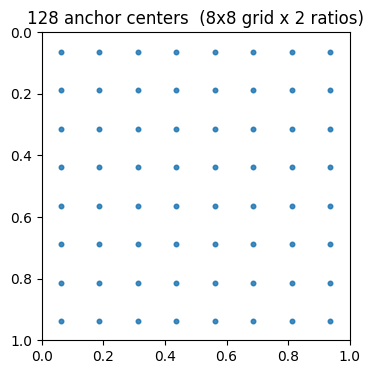

In [5]:
# quick visual sanity check of the anchor grid
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(anchors_center[:, 0], anchors_center[:, 1], s=10, alpha=0.6)
ax.set_xlim(0, 1)
ax.set_ylim(1, 0)
ax.set_aspect("equal")
ax.set_title(f"{anchors_center.shape[0]} anchor centers  ({GRID_SIZE}x{GRID_SIZE} grid x {NUM_ANCHORS_PER_CELL} ratios)")
plt.show()

## 3 — Backbone: Truncated MobileNetV2, Width-Aware

`build_truncated_backbone` slices `torchvision`'s MobileNetV2 features at `CUT_INDEX`, and loads
the ImageNet-pretrained checkpoint only when `width_mult=1.0` — torchvision doesn't ship a
checkpoint at any other width. Section 4 calls this once for the teacher (`TEACHER_WIDTH_MULT=1.0`,
pretrained) and once for the student (`STUDENT_WIDTH_MULT=0.3`, from scratch, same as the base
notebook). Channel inference downstream doesn't care which path was taken, so this one function
covers both.

In [6]:
import torch.nn as nn
import torchvision


def build_truncated_backbone(width_mult: float = WIDTH_MULT) -> nn.Module:
    if width_mult == 1.0:
        full = torchvision.models.mobilenet_v2(weights=torchvision.models.MobileNet_V2_Weights.IMAGENET1K_V1)
        print("backbone: ImageNet-pretrained MobileNetV2 (width_mult=1.0)")
    else:
        full = torchvision.models.mobilenet_v2(weights=None, width_mult=width_mult)
        print(f"backbone: from-scratch MobileNetV2 (width_mult={width_mult}) -- "
              f"no pretrained checkpoint exists at this width")
    return nn.Sequential(*list(full.features.children())[:CUT_INDEX])


def probe_backbone_blocks(width_mult: float = 1.0, img_size: int = IMG_SIZE):
    """Prints each MobileNetV2 block's output shape -- useful for picking CUT_INDEX."""
    full = torchvision.models.mobilenet_v2(weights=None, width_mult=width_mult)
    x = torch.zeros(1, 3, img_size, img_size)
    print(f"--- block-by-block probe (width_mult={width_mult}) ---")
    with torch.no_grad():
        for i, block in enumerate(full.features):
            x = block(x)
            print(f"{i:2d}  {type(block).__name__:20s}  {tuple(x.shape)}")

## 4 — SSDLite Detection Heads & Full Model (Teacher + Student)

`SeparableHead` is the SSDLite-style depthwise-separable prediction head, unchanged. Channel
counts feeding into the two heads are *inferred* from a dummy forward pass through the backbone,
never hard-coded — that's what lets the same `SSDLiteGestureDetector` class build both the
teacher (`width_mult=1.0`) and the student (`width_mult=0.5`) below, just by passing a different
width. Both end up with the same anchor count and head *shape*, only channel width differs —
that's what makes their outputs directly comparable in the distillation loss later.

In [7]:
class SeparableHead(nn.Module):
    """SSDLite-style prediction head: depthwise 3x3 (+BN+ReLU6) -> pointwise 1x1."""

    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.depthwise = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1,
                                    groups=in_channels, bias=False)
        self.bn = nn.BatchNorm2d(in_channels)
        self.act = nn.ReLU6(inplace=True)
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=True)

    def forward(self, x):
        x = self.act(self.bn(self.depthwise(x)))
        return self.pointwise(x)


def reshape_head_output(x, num_anchors_per_cell: int, out_per_anchor: int):
    """(B, A_cell*K, H, W) -> (B, H*W*A_cell, K), row-major cells then ratio-within-cell."""
    B, _, H, W = x.shape
    x = x.view(B, num_anchors_per_cell, out_per_anchor, H, W)
    x = x.permute(0, 3, 4, 1, 2).contiguous()          # (B, H, W, A_cell, K)
    return x.view(B, H * W * num_anchors_per_cell, out_per_anchor)


class SSDLiteGestureDetector(nn.Module):
    def __init__(self, num_classes: int = NUM_CLASSES, width_mult: float = WIDTH_MULT,
                 num_anchors_per_cell: int = NUM_ANCHORS_PER_CELL, img_size: int = IMG_SIZE):
        super().__init__()
        self.num_classes = num_classes
        self.num_anchors_per_cell = num_anchors_per_cell
        self.width_mult = width_mult               # stored on the instance, not read from the
                                                     # global at print time -- matters once there's
                                                     # more than one model instance at different
                                                     # widths, like the teacher/student pair here

        self.backbone = build_truncated_backbone(width_mult)

        # channel count is *inferred*, never hard-coded, so width_mult stays a single knob
        with torch.no_grad():
            feat = self.backbone(torch.zeros(1, 3, img_size, img_size))
        in_channels, grid = feat.shape[1], feat.shape[2]
        self.in_channels, self.grid_size = in_channels, grid

        self.cls_head = SeparableHead(in_channels, num_anchors_per_cell * (num_classes + 1))
        self.loc_head = SeparableHead(in_channels, num_anchors_per_cell * 4)

    def forward(self, x):
        feat = self.backbone(x)
        cls_out = reshape_head_output(self.cls_head(feat), self.num_anchors_per_cell, self.num_classes + 1)
        loc_out = reshape_head_output(self.loc_head(feat), self.num_anchors_per_cell, 4)
        return cls_out, loc_out                         # (B, num_anchors, C+1), (B, num_anchors, 4)

    def param_summary(self):
        def n(m):
            return sum(p.numel() for p in m.parameters())

        bb, cls_h, loc_h = n(self.backbone), n(self.cls_head), n(self.loc_head)
        total = bb + cls_h + loc_h
        print(f"{'backbone (mbv2 features[:14])':35s} {bb:>8,}")
        print(f"{'classification head':35s} {cls_h:>8,}")
        print(f"{'localization head':35s} {loc_h:>8,}")
        print("-" * 44)
        print(f"{'TOTAL':35s} {total:>8,}   (width_mult={self.width_mult}; original on-device "
              f"budget was ~100,000 @ width_mult=0.35)")
        return total

In [8]:
print("=== Teacher (width_mult={:.2f}, ImageNet-pretrained) ===".format(TEACHER_WIDTH_MULT))
teacher_model = SSDLiteGestureDetector(width_mult=TEACHER_WIDTH_MULT).to(device)
teacher_model.param_summary()

teacher_model.eval()
with torch.no_grad():
    _cls, _loc = teacher_model(torch.randn(4, 3, IMG_SIZE, IMG_SIZE, device=device))
print(f"forward OK -> cls {tuple(_cls.shape)}   loc {tuple(_loc.shape)}")

print(f"\n=== Student (width_mult={STUDENT_WIDTH_MULT}, from scratch -- this is the deployable one) ===")
student_model = SSDLiteGestureDetector(width_mult=STUDENT_WIDTH_MULT).to(device)
student_model.param_summary()

student_model.eval()
with torch.no_grad():
    _cls, _loc = student_model(torch.randn(4, 3, IMG_SIZE, IMG_SIZE, device=device))
print(f"forward OK -> cls {tuple(_cls.shape)}   loc {tuple(_loc.shape)}")

# both share the exact same anchor grid/count (only width/init differ), which is what makes
# per-anchor teacher-student output comparison in the distillation loss (Section 8b) valid
assert teacher_model.num_anchors_per_cell == student_model.num_anchors_per_cell

=== Teacher (width_mult=1.00, ImageNet-pretrained) ===
backbone: ImageNet-pretrained MobileNetV2 (width_mult=1.0)
backbone (mbv2 features[:14])        542,528
classification head                    2,414
localization head                      1,832
--------------------------------------------
TOTAL                                546,774   (width_mult=1.0; original on-device budget was ~100,000 @ width_mult=0.35)
forward OK -> cls (4, 128, 7)   loc (4, 128, 4)

=== Student (width_mult=0.3, from scratch -- this is the deployable one) ===
backbone: from-scratch MobileNetV2 (width_mult=0.3) -- no pretrained checkpoint exists at this width
backbone (mbv2 features[:14])         85,440
classification head                      814
localization head                        616
--------------------------------------------
TOTAL                                 86,870   (width_mult=0.3; original on-device budget was ~100,000 @ width_mult=0.35)
forward OK -> cls (4, 128, 7)   loc (4, 128, 4)


## 5 — Target Assignment (Anchor ↔ Ground-Truth Matching)

Box regression targets are encoded relative to their matched anchor (standard SSD
parameterization, scaled by `VARIANCES`). Matching is fully vectorized across the batch — every
image has exactly one ground-truth box, so `box_iou_batch` broadcasts `(B,4)` against `(A,4)` in a
single shot with no per-image Python loop. Anchors with IoU ≥ 0.5 are positive, IoU < 0.4 are
explicitly background, and the gap between is ignored (excluded from the loss entirely). The
single best-IoU anchor per image is always forced positive so every image contributes at least
one positive, even if no anchor clears 0.5.

In [9]:
def encode_boxes(gt_center, anchor_center, variances=VARIANCES):
    """Ground-truth center-form boxes -> SSD-style regression targets relative to their anchor."""
    g_cx, g_cy, g_w, g_h = gt_center.unbind(-1)
    a_cx, a_cy, a_w, a_h = anchor_center.unbind(-1)
    v1, v2, v3, v4 = variances
    t_cx = (g_cx - a_cx) / a_w / v1
    t_cy = (g_cy - a_cy) / a_h / v2
    t_w = torch.log(g_w / a_w) / v3
    t_h = torch.log(g_h / a_h) / v4
    return torch.stack([t_cx, t_cy, t_w, t_h], dim=-1)


def decode_boxes(pred_offsets, anchor_center, variances=VARIANCES):
    """Inverse of encode_boxes -- predicted offsets + anchor -> absolute center-form box."""
    t_cx, t_cy, t_w, t_h = pred_offsets.unbind(-1)
    a_cx, a_cy, a_w, a_h = anchor_center.unbind(-1)
    v1, v2, v3, v4 = variances
    p_cx = t_cx * v1 * a_w + a_cx
    p_cy = t_cy * v2 * a_h + a_cy
    p_w = torch.exp(t_w * v3) * a_w
    p_h = torch.exp(t_h * v4) * a_h
    return torch.stack([p_cx, p_cy, p_w, p_h], dim=-1)


def match_anchors_to_targets(gt_boxes_corner, gt_labels, anchors_center, anchors_corner,
                              pos_iou_thresh=POS_IOU_THRESH, neg_iou_thresh=NEG_IOU_THRESH):
    """
    Vectorized single-object-per-image anchor matching.
      gt_boxes_corner: (B,4) normalized (x1,y1,x2,y2)
      gt_labels:       (B,)  0-indexed foreground class id
    Returns:
      cls_targets: (B,A) long  -- 0=background, 1..num_classes=foreground, -1=ignore
      loc_targets: (B,A,4)     -- encoded regression targets (only valid where pos_mask is True)
      pos_mask:    (B,A) bool
      ignore_mask: (B,A) bool  -- 0.4 <= iou < 0.5, excluded from the loss entirely
    """
    B, A = gt_boxes_corner.shape[0], anchors_center.shape[0]

    iou = box_iou_batch(gt_boxes_corner, anchors_corner)            # (B,A)

    pos_mask = iou >= pos_iou_thresh
    forced_idx = iou.argmax(dim=1, keepdim=True)                    # guarantee >=1 positive/image
    pos_mask.scatter_(1, forced_idx, True)

    neg_mask = (iou < neg_iou_thresh) & (~pos_mask)
    ignore_mask = (~pos_mask) & (~neg_mask)

    cls_targets = torch.zeros(B, A, dtype=torch.long, device=gt_boxes_corner.device)
    cls_targets[pos_mask] = (gt_labels.unsqueeze(1).expand(B, A) + 1)[pos_mask]
    cls_targets[ignore_mask] = -1

    gt_center = corner_to_center(gt_boxes_corner)                   # (B,4)
    gt_center_exp = gt_center.unsqueeze(1).expand(B, A, 4)
    anchor_center_exp = anchors_center.unsqueeze(0).expand(B, A, 4)
    loc_targets = encode_boxes(gt_center_exp, anchor_center_exp)    # (B,A,4)

    return cls_targets, loc_targets, pos_mask, ignore_mask

In [10]:
# round-trip check: encode then decode should recover the original box exactly
dummy_gt = torch.rand(5, 4) * 0.5 + 0.25
dummy_anchor = anchors_center[:5]
encoded = encode_boxes(dummy_gt, dummy_anchor)
decoded = decode_boxes(encoded, dummy_anchor)
assert torch.allclose(dummy_gt, decoded, atol=1e-5), "encode/decode round-trip failed!"
print("encode/decode round-trip OK")

encode/decode round-trip OK


## 6 — MultiBox Loss (Smooth L1 + Cross-Entropy, 3:1 Hard Negative Mining)

Localization loss only ever touches matched-positive anchors — `loc_preds[pos_mask]` masks the
rest out entirely. For classification, every anchor gets a per-element cross-entropy loss first;
positive and ignored anchors are excluded from the negative-mining pool via `-inf`, then a
double-argsort (sort, then sort the sort) gives each remaining background anchor its rank by loss
magnitude with no Python loop over the batch or anchors. Keeping the top `3 * num_positives`
hardest negatives per image enforces the 3:1 ratio exactly, even when the ratio would require a
different cutoff per image in the batch.

In [11]:
import torch.nn.functional as F


class MultiBoxLoss(nn.Module):
    def __init__(self, neg_pos_ratio: int = NEG_POS_RATIO):
        super().__init__()
        self.neg_pos_ratio = neg_pos_ratio

    def forward(self, cls_preds, loc_preds, cls_targets, loc_targets, pos_mask, ignore_mask):
        B, A, C = cls_preds.shape

        # ---- localization: positives only ----
        loc_loss = F.smooth_l1_loss(loc_preds[pos_mask], loc_targets[pos_mask], reduction="sum")

        # ---- classification with 3:1 hard negative mining ----
        safe_targets = cls_targets.clamp(min=0)   # -1 (ignore) -> 0 just so CE doesn't error; excluded below
        loss_per_anchor = F.cross_entropy(
            cls_preds.view(-1, C), safe_targets.view(-1), reduction="none"
        ).view(B, A)

        loss_for_ranking = loss_per_anchor.clone()
        loss_for_ranking[pos_mask] = float("-inf")     # never select positives as "negatives"
        loss_for_ranking[ignore_mask] = float("-inf")  # never select ignored anchors either

        num_pos = pos_mask.sum(dim=1, keepdim=True)                          # (B,1)
        num_neg_avail = (~pos_mask & ~ignore_mask).sum(dim=1, keepdim=True)
        num_neg = torch.clamp(self.neg_pos_ratio * num_pos, max=num_neg_avail)

        _, loss_idx = loss_for_ranking.sort(dim=1, descending=True)
        _, rank = loss_idx.sort(dim=1)               # rank[b,a] = position of anchor a in the sorted order
        hard_neg_mask = rank < num_neg

        selected = pos_mask | hard_neg_mask
        cls_loss = loss_per_anchor[selected].sum()

        num_pos_total = num_pos.sum().clamp(min=1).float()
        loc_loss = loc_loss / num_pos_total
        cls_loss = cls_loss / num_pos_total
        return loc_loss + cls_loss, loc_loss, cls_loss

In [12]:
# sanity check with random dummy predictions
criterion = MultiBoxLoss().to(device)
dummy_cls = torch.randn(4, NUM_TOTAL_ANCHORS, NUM_CLASSES + 1, device=device)
dummy_loc = torch.randn(4, NUM_TOTAL_ANCHORS, 4, device=device)
dummy_boxes = (torch.rand(4, 4, device=device) * 0.5 + 0.25)
dummy_labels = torch.randint(0, NUM_CLASSES, (4,), device=device)

cls_t, loc_t, pos_m, ign_m = match_anchors_to_targets(dummy_boxes, dummy_labels, anchors_center_d, anchors_corner_d)
total_loss, loc_loss, cls_loss = criterion(dummy_cls, dummy_loc, cls_t, loc_t, pos_m, ign_m)
print(f"dummy loss -> total={total_loss.item():.4f}  loc={loc_loss.item():.4f}  cls={cls_loss.item():.4f}")

dummy loss -> total=nan  loc=nan  cls=16.7982


## 7 — Real Dataset: HaGRID (images) + MediaPipe Hand Landmarker (boxes)

The `cj-mills/hagrid-sample-30k-384p` variant used here has no `bboxes` column (image + label
only), so ground-truth boxes are pseudo-labeled by running MediaPipe's Hand Landmarker — a real
trained detector, not a color heuristic — on each kept image and taking the largest detected
hand's bounding box (padded 10%). The gesture *class* label still comes from HaGRID itself;
MediaPipe only supplies the box.

The MediaPipe pass takes a long time (tens of minutes for a few thousand images), so its output is
cached to disk (`DATASET_CACHE_DIR`, now under a dedicated top-level `dataset/` folder rather than
inside `models/`) and reused on subsequent runs instead of being recomputed every time.
`prepare_dataset()` also checks for a dataset already cached at the *old* `models/`-based location
from a previous run of this notebook, and moves it into `dataset/` instead of recomputing —
migration, not deletion. A `classes.txt` (one class name per line, same order as `CLASS_NAMES`)
gets written into `dataset/` alongside the data so the folder is self-describing.

**Progress bars added here:** the per-class capping loop and the MediaPipe detection loop both
report progress now — the capping loop used to run silent, and the MediaPipe loop is the single
longest step in the whole notebook.

**Memory fix:** the previous version loaded every kept image into a Python list up front
(`images_in_memory = capped["image"]`) before running detection on any of them — for ~4,800 images
that's a multi-GB spike held in RAM simultaneously, on top of Python, PyTorch, MediaPipe, and
whatever else is running. On an 8 GB machine that's enough to push the system into swap, which
looks exactly like a hang: CPU usage drops, nothing crashes, nothing progresses. This version pulls
one image at a time inside the detection loop instead, so peak memory stays roughly constant
regardless of dataset size.

**New in this notebook: training-time augmentation.** `HaGRIDGestureDataset` now takes an
`augment` flag — on for the train split, off for val. Three box-coordinate-aware transforms,
applied in order: random horizontal flip, random scale jitter (±15%, zoom in/out around center),
then color jitter (brightness/contrast/saturation/hue) last since it doesn't touch geometry. None
of your 6 classes are direction-sensitive (`point` is one class regardless of which way the finger
points), so flipping is safe here — that wouldn't hold if you ever split gestures by handedness.
Section 7c below renders a few augmented training samples with their boxes drawn, specifically so
you can eyeball that the box transforms are correct before spending a full training run on it.

In [13]:
import shutil
import time

from datasets import load_dataset, load_from_disk
from huggingface_hub import login

# ---------------------------------------------------------------------------
# mediapipe import guard
# ---------------------------------------------------------------------------
# A NameError like "name 'audio_classifier' is not defined" raised from inside
# mediapipe's own __init__.py (not from your code) means the *installed package*
# is broken -- it is not something this notebook's code can work around. The two
# usual causes:
#   1. A local file/folder named `mediapipe.py` or `mediapipe/` somewhere on
#      sys.path (often the project root, i.e. os.getcwd()) is shadowing the real
#      installed package.
#   2. A corrupted/partial pip install (very common on Windows if a previous
#      mediapipe process still had files locked during install/upgrade).
# This cell checks for (1) automatically and gives an actionable message for (2).
import importlib.util as _ilu
import os as _os

_shadow = _os.path.join(_os.getcwd(), "mediapipe.py")
if _os.path.exists(_shadow):
    raise RuntimeError(
        f"Found {_shadow} -- this file is shadowing the real 'mediapipe' package "
        "and must be renamed or deleted before mediapipe can be imported."
    )

try:
    import mediapipe as mp
    from mediapipe.tasks import python as mp_python
    from mediapipe.tasks.python import vision as mp_vision
except NameError as e:
    raise RuntimeError(
        "mediapipe failed to import cleanly (this is a broken local install, not a "
        "notebook bug). Fix it in a terminal (not this notebook) with:\n"
        "    pip uninstall -y mediapipe\n"
        "    pip cache purge\n"
        "    pip install --no-cache-dir mediapipe==0.10.14\n"
        "then restart the kernel and re-run this cell. If it still fails, check for a "
        "stray mediapipe.py/mediapipe/ file on sys.path (see check above) and that no "
        "other package (e.g. an old 'mp' alias) is colliding with it."
    ) from e


# ---------------------------------------------------------------------------
# HaGRID download + per-class capping
# ---------------------------------------------------------------------------

def _load_raw_hagrid():
    hf_token = os.environ.get("HF_TOKEN")
    if hf_token:
        login(token=hf_token)
        print("logged in to Hugging Face Hub via HF_TOKEN env var")

    print(f"downloading / loading cached copy of {HF_DATASET_ID} ...")
    raw_ds = load_dataset(HF_DATASET_ID)

    hagrid_label_names = [name.replace("train_val_", "")
                           for name in raw_ds["train"].features["label"].names]
    print("HaGRID classes in this sample:", hagrid_label_names)
    return raw_ds, hagrid_label_names


def _cap_per_class(raw_ds, hagrid_label_names):
    all_labels = raw_ds["train"]["label"]
    print(f"read {len(all_labels)} labels")

    rng = random.Random(SEED)
    by_class_idx = {c: [] for c in WANTED_HAGRID_CLASSES}
    order = list(range(len(all_labels)))
    rng.shuffle(order)

    pbar = tqdm(order, desc="capping per class")
    for i in pbar:
        cname = hagrid_label_names[all_labels[i]]
        if cname in WANTED_HAGRID_CLASSES and len(by_class_idx[cname]) < MAX_IMAGES_PER_CLASS:
            by_class_idx[cname].append(i)
        if all(len(v) >= MAX_IMAGES_PER_CLASS for v in by_class_idx.values()):
            pbar.set_postfix(status="cap reached, stopping early")
            break

    keep_indices = sorted(idx for idxs in by_class_idx.values() for idx in idxs)
    capped = raw_ds["train"].select(keep_indices)

    print("materializing the capped subset into its own compact file...")
    capped = capped.flatten_indices()

    print("per-class counts after capping:", {c: len(v) for c, v in by_class_idx.items()})
    print(f"total images going into box extraction: {len(capped)}")
    return capped


# ---------------------------------------------------------------------------
# MediaPipe Hand Landmarker pseudo-labeling
# ---------------------------------------------------------------------------

def _detect_hand_bbox(landmarker, pil_image, pad_frac=0.10):
    """
    Runs the real Hand Landmarker (not a color heuristic) on one PIL image.
    Returns (x1, y1, x2, y2) normalized to [0,1], or None if no hand found.

    If multiple hands are detected, picks the one with the larger bounding box -- the
    gesture-performing hand is usually the more prominent one. MediaPipe has no way to
    know which hand matches this row's *label*, only that a hand is present, so this is
    still a heuristic pick, just a much more reliable one than color thresholding.
    """
    rgb = np.array(pil_image.convert("RGB"))
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    result = landmarker.detect(mp_image)

    if not result.hand_landmarks:
        return None

    candidates = []
    for hand in result.hand_landmarks:
        xs = [lm.x for lm in hand]
        ys = [lm.y for lm in hand]
        x1, y1, x2, y2 = min(xs), min(ys), max(xs), max(ys)
        candidates.append((x1, y1, x2, y2, (x2 - x1) * (y2 - y1)))

    x1, y1, x2, y2, _ = max(candidates, key=lambda c: c[4])   # largest box wins

    pw, ph = (x2 - x1) * pad_frac, (y2 - y1) * pad_frac
    x1, x2 = max(0.0, x1 - pw), min(1.0, x2 + pw)
    y1, y2 = max(0.0, y1 - ph), min(1.0, y2 + ph)
    return (x1, y1, x2, y2)


def _extract_boxes_with_mediapipe(capped, hagrid_label_names):
    if not os.path.exists(MEDIAPIPE_MODEL_PATH):
        import urllib.request
        print(f"downloading hand landmarker model to {MEDIAPIPE_MODEL_PATH} ...")
        urllib.request.urlretrieve(MEDIAPIPE_MODEL_URL, MEDIAPIPE_MODEL_PATH)
        print(f"  done, {os.path.getsize(MEDIAPIPE_MODEL_PATH) / 1e6:.1f} MB")
    else:
        print(f"model already present at {MEDIAPIPE_MODEL_PATH}")

    base_options = mp_python.BaseOptions(model_asset_path=MEDIAPIPE_MODEL_PATH)
    landmarker_options = mp_vision.HandLandmarkerOptions(
        base_options=base_options,
        num_hands=2,
        running_mode=mp_vision.RunningMode.IMAGE,
    )
    landmarker = mp_vision.HandLandmarker.create_from_options(landmarker_options)

    # pull one row at a time instead of `capped["image"]`, which decodes every image in the
    # split into a Python list up front -- for a few thousand images that's a multi-GB spike
    # held in RAM simultaneously, on top of PyTorch/MediaPipe/everything else already running.
    # on an 8GB machine that's enough to push the system into swap, which looks exactly like a
    # hang: CPU usage drops, nothing crashes, nothing progresses. streaming keeps peak memory
    # roughly constant regardless of dataset size.
    n_images = len(capped)
    final_boxes, keep_mask = [], []
    pbar = tqdm(range(n_images), desc="MediaPipe hand detection", unit="img")
    t0 = time.time()
    for i in pbar:
        img = capped[i]["image"]
        box = _detect_hand_bbox(landmarker, img)
        keep_mask.append(box is not None)
        final_boxes.append(box)
        n_done = len(final_boxes)
        pbar.set_postfix(hit_rate=f"{sum(keep_mask) / n_done:.0%}")
    elapsed = time.time() - t0
    print(f"  done in {elapsed:.1f}s  ({elapsed / max(n_images, 1) * 1000:.0f} ms/image)")

    n_found = sum(keep_mask)
    print(f"hand detected in {n_found}/{n_images} images ({n_found / n_images:.1%})")

    detected_indices = [i for i, keep in enumerate(keep_mask) if keep]
    final_ds = capped.select(detected_indices)
    final_ds = final_ds.add_column("bbox", [final_boxes[i] for i in detected_indices])

    class_counts = {c: 0 for c in CLASS_NAMES}
    for lbl in final_ds["label"]:
        class_counts[HAGRID_TO_PROJECT[hagrid_label_names[lbl]]] += 1
    print("final class balance:", class_counts)
    return final_ds


# ---------------------------------------------------------------------------
# Training-time augmentation (box-coordinate-aware)
# ---------------------------------------------------------------------------

_COLOR_JITTER = torchvision.transforms.ColorJitter(brightness=0.25, contrast=0.25,
                                                      saturation=0.2, hue=0.02)


def _hflip(img, box_norm):
    """50% chance horizontal flip. Safe for this class list -- none of CLASS_NAMES are
    direction-sensitive (`point` is one class regardless of which way the finger points)."""
    if random.random() < 0.5:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
        x1, y1, x2, y2 = box_norm
        box_norm = np.array([1.0 - x2, y1, 1.0 - x1, y2], dtype=np.float32)
    return img, box_norm


def _scale_jitter(img, box_norm, scale_range=(0.85, 1.15)):
    """
    Zooms in/out around the image center by a random factor and returns an image of the
    same size. A point at normalized position p maps to 0.5 + (p-0.5)*scale regardless of
    zoom direction -- only the PIL operation differs (crop+resize to zoom in,
    shrink+pad to zoom out). img must already be square (IMG_SIZE x IMG_SIZE).
    """
    scale = random.uniform(*scale_range)
    S = img.size[0]

    if scale >= 1.0:
        crop = S / scale
        left = top = (S - crop) / 2
        img = img.crop((left, top, left + crop, top + crop)).resize((S, S), Image.BILINEAR)
    else:
        new_s = max(1, int(S * scale))
        img_small = img.resize((new_s, new_s), Image.BILINEAR)
        pad_color = tuple(np.array(img).reshape(-1, 3).mean(axis=0).astype(int).tolist())
        canvas = Image.new("RGB", (S, S), pad_color)
        canvas.paste(img_small, ((S - new_s) // 2, (S - new_s) // 2))
        img = canvas

    x1, y1, x2, y2 = box_norm
    x1, x2 = 0.5 + (x1 - 0.5) * scale, 0.5 + (x2 - 0.5) * scale
    y1, y2 = 0.5 + (y1 - 0.5) * scale, 0.5 + (y2 - 0.5) * scale
    return img, np.clip([x1, y1, x2, y2], 0.0, 1.0).astype(np.float32)


def augment_sample(img, box_norm):
    """img: PIL Image already resized to IMG_SIZE x IMG_SIZE. box_norm: [x1,y1,x2,y2] in [0,1]."""
    img, box_norm = _hflip(img, box_norm)
    img, box_norm = _scale_jitter(img, box_norm)
    img = _COLOR_JITTER(img)   # geometry-independent -- always last
    return img, box_norm


# ---------------------------------------------------------------------------
# PyTorch Dataset / DataLoaders
# ---------------------------------------------------------------------------

class HaGRIDGestureDataset(torch.utils.data.Dataset):
    def __init__(self, hf_split, hagrid_label_names, img_size: int = IMG_SIZE, augment: bool = False):
        self.ds = hf_split
        self.hagrid_label_names = hagrid_label_names
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        row = self.ds[idx]
        img = row["image"]
        if img.mode != "RGB":
            img = img.convert("RGB")
        img = img.resize((self.img_size, self.img_size), Image.BILINEAR)

        box_norm = np.array(row["bbox"], dtype=np.float32)
        box_norm = np.clip(box_norm, 0.0, 1.0)

        if self.augment:
            img, box_norm = augment_sample(img, box_norm)

        box_t = torch.from_numpy(box_norm).clamp(0.0, 1.0)

        label_name = HAGRID_TO_PROJECT[self.hagrid_label_names[row["label"]]]
        label_t = torch.tensor(CLASS_NAMES.index(label_name), dtype=torch.long)

        image_t = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
        return image_t, box_t, label_t


def prepare_dataset(force_rebuild: bool = False, augment_train: bool = True):
    """
    Returns (train_loader, val_loader, hagrid_label_names).

    Caches the MediaPipe-pseudo-labeled dataset to DATASET_CACHE_DIR (under the top-level
    dataset/ folder) so the (slow) MediaPipe pass only ever runs once per
    MAX_IMAGES_PER_CLASS/SEED combination. Pass force_rebuild=True to ignore an existing cache
    and recompute it.

    If a dataset from an older run of this notebook is still sitting at the legacy
    models/hagrid_pseudo_labeled location, it gets moved into dataset/ instead of recomputed.

    augment_train=True applies random flip/scale/color augmentation to the train split only.
    """
    raw_ds, hagrid_label_names = _load_raw_hagrid()   # cheap; needed either way for label names

    if (not os.path.isdir(DATASET_CACHE_DIR)) and os.path.isdir(_LEGACY_DATASET_CACHE_DIR):
        print(f"found a dataset cached at the old location ({_LEGACY_DATASET_CACHE_DIR}) -- "
              f"moving it to {DATASET_CACHE_DIR} instead of recomputing it")
        shutil.move(_LEGACY_DATASET_CACHE_DIR, DATASET_CACHE_DIR)

    if os.path.isdir(DATASET_CACHE_DIR) and not force_rebuild:
        print(f"found cached pseudo-labeled dataset at {DATASET_CACHE_DIR}, skipping MediaPipe pass")
        final_ds = load_from_disk(DATASET_CACHE_DIR)
    else:
        capped = _cap_per_class(raw_ds, hagrid_label_names)
        final_ds = _extract_boxes_with_mediapipe(capped, hagrid_label_names)
        print(f"caching pseudo-labeled dataset to {DATASET_CACHE_DIR} for future runs...")
        final_ds.save_to_disk(DATASET_CACHE_DIR)

    if not os.path.exists(CLASSES_FILE):
        with open(CLASSES_FILE, "w") as f:
            f.write("\n".join(CLASS_NAMES) + "\n")
        print(f"wrote class list to {CLASSES_FILE}")

    final_ds = final_ds.shuffle(seed=SEED)
    n_val = max(1, int(0.1 * len(final_ds)))
    hf_val = final_ds.select(range(n_val))
    hf_train = final_ds.select(range(n_val, len(final_ds)))
    print(f"train: {len(hf_train)}   val: {len(hf_val)}   (augment_train={augment_train})")

    train_ds = HaGRIDGestureDataset(hf_train, hagrid_label_names, augment=augment_train)
    val_ds = HaGRIDGestureDataset(hf_val, hagrid_label_names, augment=False)

    train_loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                                                 num_workers=0, pin_memory=torch.cuda.is_available())
    val_loader = torch.utils.data.DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                                               num_workers=0, pin_memory=torch.cuda.is_available())

    imgs, boxes, labels = next(iter(train_loader))
    print("batch:", tuple(imgs.shape), tuple(boxes.shape), tuple(labels.shape))

    return train_loader, val_loader, hagrid_label_names

In [14]:
from PIL import Image

train_loader, val_loader, hagrid_label_names = prepare_dataset()

downloading / loading cached copy of cj-mills/hagrid-sample-30k-384p ...
HaGRID classes in this sample: ['call', 'dislike', 'fist', 'four', 'like', 'mute', 'ok', 'one', 'palm', 'peace', 'peace_inverted', 'rock', 'stop', 'stop_inverted', 'three', 'three2', 'two_up', 'two_up_inverted']
found cached pseudo-labeled dataset at c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\dataset\hagrid_pseudo_labeled, skipping MediaPipe pass
train: 3906   val: 433   (augment_train=True)
batch: (64, 3, 128, 128) (64, 4) (64,)


## 7b — Refit Anchors to the Real Box Distribution

`ANCHOR_BASE_PX = 48` and `ASPECT_RATIOS = (1.0, 1.8)` in Section 1 were hand-picked guesses.
Now that the dataset is loaded, its `bbox` column has the real answer — measure actual box size
and aspect ratio directly instead of guessing. The anchor *count* stays at 2 per cell (so nothing
about the head architecture changes, only the anchor geometry), using the 25th/75th percentile of
the real width/height ratio as the two representative aspect ratios, and the median box scale
(√(w·h)) as the base size. `anchors_center`/`anchors_corner` (and their `_d` device copies) get
regenerated in place with the fitted numbers, overriding Section 2's placeholder anchors —
everything downstream (matching, loss, model heads) already reads from these same variable names,
so nothing else needs to change.

In [15]:
def _box_wh_px(hf_split):
    boxes = np.array(hf_split["bbox"], dtype=np.float32)   # (N,4) x1,y1,x2,y2 normalized
    w = (boxes[:, 2] - boxes[:, 0]) * IMG_SIZE
    h = (boxes[:, 3] - boxes[:, 1]) * IMG_SIZE
    return w, h

w_train, h_train = _box_wh_px(train_loader.dataset.ds)
w_val, h_val = _box_wh_px(val_loader.dataset.ds)
w_all = np.concatenate([w_train, w_val])
h_all = np.concatenate([h_train, h_val])
ratio_all = w_all / h_all
scale_all = np.sqrt(w_all * h_all)

print(f"box width  (px): min={w_all.min():.1f}  median={np.median(w_all):.1f}  max={w_all.max():.1f}")
print(f"box height (px): min={h_all.min():.1f}  median={np.median(h_all):.1f}  max={h_all.max():.1f}")
print(f"box w/h ratio:    min={ratio_all.min():.2f}  median={np.median(ratio_all):.2f}  max={ratio_all.max():.2f}")

fitted_base_px = float(np.median(scale_all))
fitted_ratio_lo = float(np.percentile(ratio_all, 25))
fitted_ratio_hi = float(np.percentile(ratio_all, 75))

print(f"\nold  ANCHOR_BASE_PX={ANCHOR_BASE_PX}   ASPECT_RATIOS={ASPECT_RATIOS}")
print(f"new  ANCHOR_BASE_PX={fitted_base_px:.1f}   ASPECT_RATIOS=({fitted_ratio_lo:.2f}, {fitted_ratio_hi:.2f})")

ANCHOR_BASE_PX = fitted_base_px
ASPECT_RATIOS = (fitted_ratio_lo, fitted_ratio_hi)

anchors_center = generate_anchors(IMG_SIZE, STRIDE, ANCHOR_BASE_PX, ASPECT_RATIOS)
anchors_corner = center_to_corner(anchors_center)
anchors_center_d = anchors_center.to(device)
anchors_corner_d = anchors_corner.to(device)
print(f"\nanchors regenerated: {tuple(anchors_center.shape)}  (count unchanged, geometry refit)")

box width  (px): min=1.9  median=15.1  max=74.1
box height (px): min=4.9  median=19.8  max=106.4
box w/h ratio:    min=0.15  median=0.84  max=3.47

old  ANCHOR_BASE_PX=48   ASPECT_RATIOS=(1.0, 1.8)
new  ANCHOR_BASE_PX=17.1   ASPECT_RATIOS=(0.57, 1.08)

anchors regenerated: (128, 4)  (count unchanged, geometry refit)


## 7c — Sanity-Check the Augmentation

Renders 6 random *training-split* samples with augmentation applied and their box drawn, so you
can confirm the flip/scale transforms are moving the box correctly before committing a full
training run to it. If any box looks visibly off relative to the hand in the image, stop here —
don't train on it.

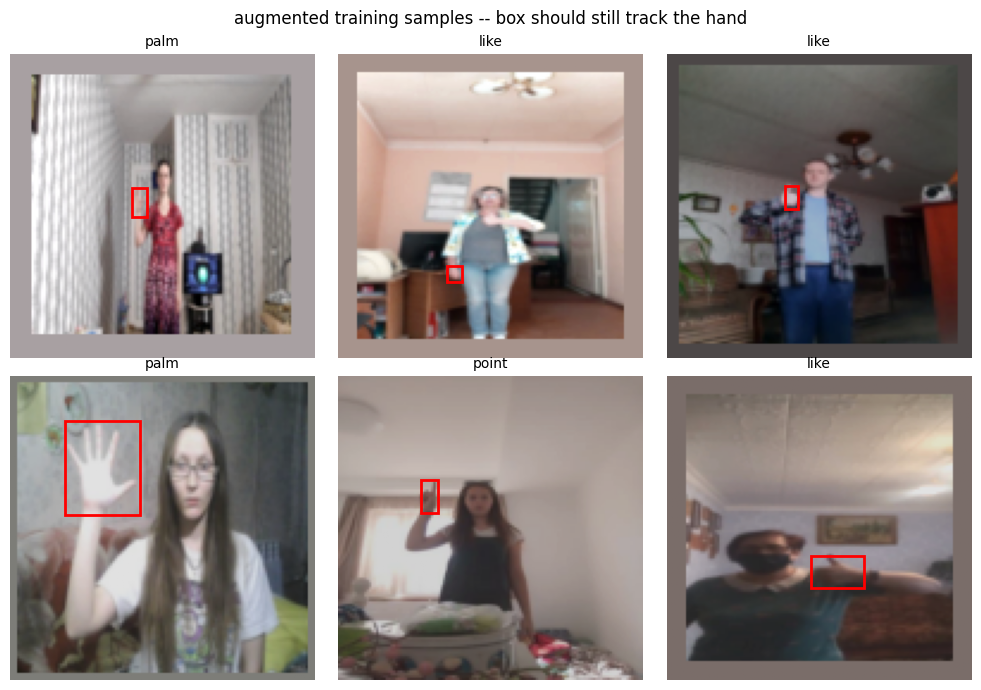

In [16]:
import matplotlib.patches as patches

train_ds_raw = train_loader.dataset
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
sample_idxs = random.sample(range(len(train_ds_raw)), 6)
for idx, ax in zip(sample_idxs, axes.flat):
    img_t, box_t, label_t = train_ds_raw[idx]
    img_np = img_t.permute(1, 2, 0).numpy()
    x1, y1, x2, y2 = (box_t * IMG_SIZE).tolist()
    ax.imshow(img_np)
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                    edgecolor="red", linewidth=2))
    ax.set_title(CLASS_NAMES[label_t.item()], fontsize=10)
    ax.axis("off")
fig.suptitle("augmented training samples -- box should still track the hand")
fig.tight_layout()
plt.show()

## 8a — Stage 1: Train the Teacher

Standard training — same `MultiBoxLoss`, same `train_model` as the base/pretrained notebooks,
just pointed at `teacher_model` with its own epoch budget (`TEACHER_EPOCHS`) and its own
checkpoint filename (`teacher_best.pt`, not `best_model.pt` — that name is reserved for the
final distilled student in 8b, so the two stages can't overwrite each other).

`SELECTION_METRIC` picks which validation metric selects the saved checkpoint — macro-F1 by
default. Per-*iteration* loss is recorded in `history["iter_total"]` etc. too, for the raw curve
instead of just epoch averages.

**Run this once, straight through.** `train_model` builds a fresh `CosineAnnealingLR` every call —
calling it again to "continue" training restarts the schedule and re-perturbs already-annealed
weights. If `val_f1` is still climbing when `TEACHER_EPOCHS` runs out, raise it in Section 1 and
rerun from here, not by calling `train_model` a second time on top of itself.

In [17]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


@torch.no_grad()
def predict_batch_labels(model, imgs, anchors_center, conf_thresh: float = 0.5):
    """
    Returns pred_labels: (B,) long tensor, project class id, or -1 if nothing cleared
    conf_thresh. Used for fast per-epoch validation (batched version of the single-image
    detector in Section 9). Works on either teacher or student -- takes any model with the
    same forward signature.
    """
    cls_preds, loc_preds = model(imgs)                       # (B,A,C+1), (B,A,4)
    probs = F.softmax(cls_preds, dim=-1)
    fg_probs = probs[..., 1:]
    best_score_per_anchor, best_cls_per_anchor = fg_probs.max(dim=-1)      # (B,A)

    thresholded = best_score_per_anchor.masked_fill(best_score_per_anchor < conf_thresh, -1.0)
    best_score, best_anchor_idx = thresholded.max(dim=-1)                  # (B,)

    pred_labels = best_cls_per_anchor.gather(1, best_anchor_idx.unsqueeze(1)).squeeze(1)
    pred_labels = torch.where(best_score >= 0, pred_labels, torch.full_like(pred_labels, -1))
    return pred_labels


@torch.no_grad()
def evaluate(model, loader, anchors_center, device, conf_thresh: float = 0.5):
    """Runs the detector over a loader and computes classification-style metrics on the
    gesture label of the single detected hand (a missed detection counts as a wrong
    prediction). Reused as-is for both teacher and student -- it only needs a model with the
    standard forward signature, doesn't care how it was trained."""
    model.eval()
    all_preds, all_gts = [], []
    for imgs, boxes, labels in tqdm(loader, desc="validating", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        preds = predict_batch_labels(model, imgs, anchors_center, conf_thresh)
        all_preds.append(preds.cpu())
        all_gts.append(labels.cpu())
    all_preds = torch.cat(all_preds).numpy()
    all_gts = torch.cat(all_gts).numpy()

    accuracy = accuracy_score(all_gts, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_gts, all_preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
    )
    n_missed = int((all_preds == -1).sum())
    return {"accuracy": accuracy, "precision": precision, "recall": recall,
            "f1_macro": f1, "n_missed": n_missed, "n_total": len(all_gts)}


def train_model(model, train_loader, val_loader, anchors_center, anchors_corner, device,
                 epochs: int = TEACHER_EPOCHS, lr: float = LR, weight_decay: float = WEIGHT_DECAY,
                 selection_metric: str = SELECTION_METRIC, checkpoint_name: str = "best_model.pt"):
    """Standard (non-distillation) training loop. `checkpoint_name` lets this be reused for
    the teacher (saved as teacher_best.pt) without colliding with the student's best_model.pt."""
    criterion = MultiBoxLoss().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {
        "total": [], "loc": [], "cls": [],
        "val_accuracy": [], "val_precision": [], "val_recall": [], "val_f1_macro": [],
        "iter_total": [], "iter_loc": [], "iter_cls": [],   # per-iteration, never reset
    }

    best_metric_value = -1.0
    best_state_dict = None
    best_epoch = -1

    epoch_bar = tqdm(range(1, epochs + 1), desc="training", unit="epoch")
    for epoch in epoch_bar:
        model.train()
        running = {"total": 0.0, "loc": 0.0, "cls": 0.0}
        n_batches = 0

        batch_bar = tqdm(train_loader, desc=f"epoch {epoch}/{epochs}", leave=False)
        for imgs, boxes, labels in batch_bar:
            imgs, boxes, labels = imgs.to(device), boxes.to(device), labels.to(device)

            cls_preds, loc_preds = model(imgs)
            cls_t, loc_t, pos_m, ign_m = match_anchors_to_targets(boxes, labels, anchors_center, anchors_corner)
            total_loss, loc_loss, cls_loss = criterion(cls_preds, loc_preds, cls_t, loc_t, pos_m, ign_m)

            optimizer.zero_grad()
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()

            history["iter_total"].append(total_loss.item())
            history["iter_loc"].append(loc_loss.item())
            history["iter_cls"].append(cls_loss.item())

            running["total"] += total_loss.item()
            running["loc"] += loc_loss.item()
            running["cls"] += cls_loss.item()
            n_batches += 1

            batch_bar.set_postfix(total=running["total"] / n_batches,
                                   loc=running["loc"] / n_batches,
                                   cls=running["cls"] / n_batches)

        scheduler.step()
        for k in ("total", "loc", "cls"):
            history[k].append(running[k] / n_batches)

        val_metrics = evaluate(model, val_loader, anchors_center, device)
        for k in ("accuracy", "precision", "recall", "f1_macro"):
            history[f"val_{k}"].append(val_metrics[k])

        is_best = val_metrics[selection_metric] > best_metric_value
        if is_best:
            best_metric_value = val_metrics[selection_metric]
            best_state_dict = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_epoch = epoch

        epoch_bar.set_postfix(total=f"{history['total'][-1]:.3f}",
                               val_f1=f"{val_metrics['f1_macro']:.3f}",
                               best=f"{best_metric_value:.3f}@{best_epoch}")

        print(f"epoch {epoch:2d}/{epochs}  total={history['total'][-1]:.4f}  "
              f"loc={history['loc'][-1]:.4f}  cls={history['cls'][-1]:.4f}  |  "
              f"val_acc={val_metrics['accuracy']:.3f}  val_prec={val_metrics['precision']:.3f}  "
              f"val_rec={val_metrics['recall']:.3f}  val_f1={val_metrics['f1_macro']:.3f}  "
              f"(missed {val_metrics['n_missed']}/{val_metrics['n_total']})"
              f"{'  <-- best so far' if is_best else ''}")

    print(f"\nbest checkpoint: epoch {best_epoch}  {selection_metric}={best_metric_value:.4f}")
    best_model_path = os.path.join(MODELS_DIR, checkpoint_name)
    torch.save(best_state_dict, best_model_path)
    model.load_state_dict(best_state_dict)   # switch the live model to the best checkpoint
    print(f"loaded best checkpoint into the passed-in model and saved it to {best_model_path}")

    return history, best_epoch, best_metric_value

In [18]:
# =============================================================================
# Teacher = TinyGestureSSD_pretrained.ipynb's own model, reused directly rather than
# retrained here. Same architecture (width_mult=1.0, ImageNet-pretrained), same dataset,
# and per Youcef's decision TEACHER_EPOCHS=60 now matches that notebook's own EPOCHS -- so
# this is not a width/epoch-matched-but-separately-trained copy, it's literally the same
# checkpoint. That guarantees the teacher this student is distilled from is exactly the
# 86.9%-F1 model already validated in the pretrained notebook, with zero risk of the two
# drifting apart from being trained twice under configs that quietly stop matching.
#
# Falls back to training a fresh teacher here (old behavior) if that notebook's checkpoint
# isn't found, so this cell still works standalone.
# =============================================================================

FORCE_RETRAIN_TEACHER = False   # set True to always retrain a fresh teacher, ignoring both
                                 # the pretrained notebook's checkpoint and any local one
teacher_ckpt_path = os.path.join(MODELS_DIR, "teacher_best.pt")

PRETRAINED_NOTEBOOK_MODELS_DIR = os.path.join(PROJECT_ROOT, "models_pretrained")
PRETRAINED_NOTEBOOK_CKPT = os.path.join(PRETRAINED_NOTEBOOK_MODELS_DIR, "best_model.pt")

if not FORCE_RETRAIN_TEACHER and os.path.exists(PRETRAINED_NOTEBOOK_CKPT):
    print(f"loading teacher from TinyGestureSSD_pretrained.ipynb's checkpoint: "
          f"{PRETRAINED_NOTEBOOK_CKPT}")
    teacher_model.load_state_dict(torch.load(PRETRAINED_NOTEBOOK_CKPT, map_location=device))
    teacher_model.to(device)
    teacher_metrics = evaluate(teacher_model, val_loader, anchors_center_d, device)
    teacher_best_f1 = teacher_metrics["f1_macro"]
    teacher_best_epoch = None   # unknown -- trained in a different notebook, no per-epoch log here
    teacher_history = None      # no training curve this run -- the plot cell below handles this
    print(f"loaded. val f1_macro={teacher_best_f1:.4f} (recomputed fresh against this notebook's "
          f"val_loader -- should match the pretrained notebook's own number if the dataset split "
          f"and preprocessing are identical, which they are)")
    # keep a local copy too, so downstream cells/reruns don't depend on the other notebook's
    # folder still being present or unmodified
    torch.save(teacher_model.state_dict(), teacher_ckpt_path)
elif not FORCE_RETRAIN_TEACHER and os.path.exists(teacher_ckpt_path):
    print(f"TinyGestureSSD_pretrained.ipynb's checkpoint not found at "
          f"{PRETRAINED_NOTEBOOK_CKPT} -- falling back to this notebook's own local teacher "
          f"checkpoint: {teacher_ckpt_path}")
    teacher_model.load_state_dict(torch.load(teacher_ckpt_path, map_location=device))
    teacher_model.to(device)
    teacher_metrics = evaluate(teacher_model, val_loader, anchors_center_d, device)
    teacher_best_f1 = teacher_metrics["f1_macro"]
    teacher_best_epoch = None
    teacher_history = None
    print(f"loaded. val f1_macro={teacher_best_f1:.4f} (recomputed fresh against current val_loader)")
else:
    print(f"no existing teacher checkpoint found anywhere ({PRETRAINED_NOTEBOOK_CKPT} or "
          f"{teacher_ckpt_path}) -- training a fresh teacher here, TEACHER_EPOCHS={TEACHER_EPOCHS}")
    teacher_history, teacher_best_epoch, teacher_best_f1 = train_model(
        teacher_model, train_loader, val_loader, anchors_center_d, anchors_corner_d, device,
        epochs=TEACHER_EPOCHS, checkpoint_name="teacher_best.pt")


loading teacher from TinyGestureSSD_pretrained.ipynb's checkpoint: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_pretrained\best_model.pt


C:\Users\xared\AppData\Local\Temp\ipykernel_25596\608747615.py:24: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  teacher_model.load_state_dict(torch.load(PRETRAINED_NOTEBOOK

validating:   0%|          | 0/7 [00:00<?, ?it/s]

loaded. val f1_macro=0.8692 (recomputed fresh against this notebook's val_loader -- should match the pretrained notebook's own number if the dataset split and preprocessing are identical, which they are)


In [19]:
if teacher_history is None:
    print("teacher was loaded from an existing checkpoint this run -- no per-epoch training "
          f"curve to plot. val f1_macro = {teacher_best_f1:.4f}")
    print("(set FORCE_RETRAIN_TEACHER = True in the cell above and rerun both cells if you "
          "need fresh training curves)")
else:
    epochs_range = range(1, len(teacher_history["total"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(epochs_range, teacher_history["total"], marker="o", label="total")
    axes[0].plot(epochs_range, teacher_history["loc"], marker="o", label="loc")
    axes[0].plot(epochs_range, teacher_history["cls"], marker="o", label="cls")
    axes[0].set_title("Teacher training loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
    axes[0].grid(alpha=0.3)

    for key, label in [("val_accuracy", "accuracy"), ("val_precision", "precision"),
                        ("val_recall", "recall"), ("val_f1_macro", "F1 (macro)")]:
        axes[1].plot(epochs_range, teacher_history[key], marker="o", label=label)
    axes[1].axvline(teacher_best_epoch, color="gray", linestyle="--", alpha=0.6,
                     label=f"best epoch ({teacher_best_epoch})")
    axes[1].set_title("Teacher validation metrics")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylim(0, 1.02)
    axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
    axes[1].grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig(os.path.join(MODELS_DIR, "teacher_training_curves.png"), dpi=150)

    print(f"teacher best epoch: {teacher_best_epoch}   {SELECTION_METRIC} = {teacher_best_f1:.4f}")
    print("this is the ceiling the student (8b) is being distilled toward -- the student "
          "shouldn't be expected to beat this, only approach it with a much smaller model.")


teacher was loaded from an existing checkpoint this run -- no per-epoch training curve to plot. val f1_macro = 0.8692
(set FORCE_RETRAIN_TEACHER = True in the cell above and rerun both cells if you need fresh training curves)


## 8b — Stage 2: Distill into the Student

`teacher_model` gets frozen (`eval()`, `requires_grad_(False)`) and run once per batch alongside
the student, purely for its outputs — no teacher gradients, no teacher weight updates from here on.

`DistillationLoss` wraps the same `MultiBoxLoss` from Section 6 (hard labels, unchanged) and adds
two soft terms pulling the student toward the teacher:
- **classification**: KL divergence between temperature-softened student/teacher class
  distributions (`KD_TEMPERATURE`, standard Hinton et al. soft-target distillation) — this is
  where the real information transfer happens, since the teacher's *relative* confidence across
  all 6 classes carries more signal than just its top prediction.
- **localization**: SmoothL1 between student and teacher box regression outputs, only at the
  positive anchors the hard loss already uses — a soft box target only makes sense where there's
  an actual box to regress toward.

Both terms are optional dials (`KD_ALPHA`, `KD_BETA` in Section 1) — set either to 0 to isolate
whether classification or localization guidance is doing the work, if the result is worth digging
into further.

This is the actual test of the AgroStake question from the title cell: does soft-target guidance
help a from-scratch `width_mult=0.5` detector converge faster/better than ground truth alone did
in the base notebook? `student_history["val_f1_macro"]` here is the number to compare directly
against the base notebook's run.

In [20]:
class DistillationLoss(nn.Module):
    """
    Hard-label MultiBoxLoss (ground truth, unchanged) plus a soft distillation term pulling
    the student toward a frozen teacher's outputs.
      - classification: KL divergence between temperature-softened student/teacher class
        distributions (Hinton et al. 2015 soft-target distillation), weighted by `alpha`.
      - localization: SmoothL1 between student and teacher box regression outputs, at the
        same positive anchors the hard loss already uses -- soft box targets only mean
        something where there's an actual box to regress -- weighted by `beta`.
    """

    def __init__(self, neg_pos_ratio: int = NEG_POS_RATIO, temperature: float = KD_TEMPERATURE,
                 alpha: float = KD_ALPHA, beta: float = KD_BETA):
        super().__init__()
        self.hard_loss = MultiBoxLoss(neg_pos_ratio=neg_pos_ratio)
        self.temperature = temperature
        self.alpha = alpha
        self.beta = beta

    def forward(self, student_cls, student_loc, teacher_cls, teacher_loc,
                cls_targets, loc_targets, pos_mask, ignore_mask):
        hard_total, hard_loc, hard_cls = self.hard_loss(
            student_cls, student_loc, cls_targets, loc_targets, pos_mask, ignore_mask)

        T = self.temperature
        student_log_soft = F.log_softmax(student_cls / T, dim=-1)
        teacher_soft = F.softmax(teacher_cls / T, dim=-1).detach()
        soft_cls = F.kl_div(student_log_soft, teacher_soft, reduction="batchmean") * (T ** 2)

        num_pos = pos_mask.sum().clamp(min=1).float()
        soft_loc = F.smooth_l1_loss(student_loc[pos_mask], teacher_loc[pos_mask].detach(),
                                     reduction="sum") / num_pos

        total = hard_total + self.alpha * soft_cls + self.beta * soft_loc
        return total, hard_loc, hard_cls, soft_cls, soft_loc

In [21]:
# sanity check with random dummy predictions -- confirms shapes/dtypes line up before spending
# real training time on it. teacher and student can differ in width but must share the exact
# same anchor count/output shape for this to make sense (asserted back in Section 4).
dummy_teacher_cls = torch.randn(4, NUM_TOTAL_ANCHORS, NUM_CLASSES + 1, device=device)
dummy_teacher_loc = torch.randn(4, NUM_TOTAL_ANCHORS, 4, device=device)
dummy_student_cls = torch.randn(4, NUM_TOTAL_ANCHORS, NUM_CLASSES + 1, device=device)
dummy_student_loc = torch.randn(4, NUM_TOTAL_ANCHORS, 4, device=device)
dummy_boxes = (torch.rand(4, 4, device=device) * 0.5 + 0.25)
dummy_labels = torch.randint(0, NUM_CLASSES, (4,), device=device)

cls_t, loc_t, pos_m, ign_m = match_anchors_to_targets(
    dummy_boxes, dummy_labels, anchors_center_d, anchors_corner_d)
kd_criterion = DistillationLoss()
total, hard_loc, hard_cls, soft_cls, soft_loc = kd_criterion(
    dummy_student_cls, dummy_student_loc, dummy_teacher_cls, dummy_teacher_loc,
    cls_t, loc_t, pos_m, ign_m)
print(f"dummy KD loss -> total={total.item():.4f}  hard_loc={hard_loc.item():.4f}  "
      f"hard_cls={hard_cls.item():.4f}  soft_cls={soft_cls.item():.4f}  soft_loc={soft_loc.item():.4f}")

dummy KD loss -> total=nan  hard_loc=nan  hard_cls=16.9036  soft_cls=108.9578  soft_loc=2.8290


In [22]:
def train_model_kd(student, teacher, train_loader, val_loader, anchors_center, anchors_corner, device,
                    epochs: int = STUDENT_EPOCHS, lr: float = LR, weight_decay: float = WEIGHT_DECAY,
                    selection_metric: str = SELECTION_METRIC, checkpoint_name: str = "best_model.pt",
                    temperature: float = KD_TEMPERATURE, alpha: float = KD_ALPHA, beta: float = KD_BETA):
    """
    Same shape as train_model, but the student is also pulled toward a frozen teacher's
    outputs via DistillationLoss. Only `student`'s parameters get gradient updates -- the
    teacher is frozen and always run in eval mode under no_grad.
    """
    teacher.eval()
    for p in teacher.parameters():
        p.requires_grad_(False)

    criterion = DistillationLoss(neg_pos_ratio=NEG_POS_RATIO, temperature=temperature,
                                   alpha=alpha, beta=beta).to(device)
    optimizer = torch.optim.AdamW(student.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {
        "total": [], "loc": [], "cls": [], "soft_cls": [], "soft_loc": [],
        "val_accuracy": [], "val_precision": [], "val_recall": [], "val_f1_macro": [],
        "iter_total": [], "iter_loc": [], "iter_cls": [], "iter_soft_cls": [], "iter_soft_loc": [],
    }

    best_metric_value = -1.0
    best_state_dict = None
    best_epoch = -1

    epoch_bar = tqdm(range(1, epochs + 1), desc="distilling", unit="epoch")
    for epoch in epoch_bar:
        student.train()
        running = {"total": 0.0, "loc": 0.0, "cls": 0.0, "soft_cls": 0.0, "soft_loc": 0.0}
        n_batches = 0

        batch_bar = tqdm(train_loader, desc=f"epoch {epoch}/{epochs}", leave=False)
        for imgs, boxes, labels in batch_bar:
            imgs, boxes, labels = imgs.to(device), boxes.to(device), labels.to(device)

            with torch.no_grad():
                teacher_cls, teacher_loc = teacher(imgs)

            student_cls, student_loc = student(imgs)
            cls_t, loc_t, pos_m, ign_m = match_anchors_to_targets(boxes, labels, anchors_center, anchors_corner)
            total_loss, hard_loc, hard_cls, soft_cls, soft_loc = criterion(
                student_cls, student_loc, teacher_cls, teacher_loc, cls_t, loc_t, pos_m, ign_m)

            optimizer.zero_grad()
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(student.parameters(), max_norm=5.0)
            optimizer.step()

            history["iter_total"].append(total_loss.item())
            history["iter_loc"].append(hard_loc.item())
            history["iter_cls"].append(hard_cls.item())
            history["iter_soft_cls"].append(soft_cls.item())
            history["iter_soft_loc"].append(soft_loc.item())

            running["total"] += total_loss.item()
            running["loc"] += hard_loc.item()
            running["cls"] += hard_cls.item()
            running["soft_cls"] += soft_cls.item()
            running["soft_loc"] += soft_loc.item()
            n_batches += 1

            batch_bar.set_postfix(total=running["total"] / n_batches,
                                   hard_cls=running["cls"] / n_batches,
                                   soft_cls=running["soft_cls"] / n_batches)

        scheduler.step()
        for k in ("total", "loc", "cls", "soft_cls", "soft_loc"):
            history[k].append(running[k] / n_batches)

        val_metrics = evaluate(student, val_loader, anchors_center, device)
        for k in ("accuracy", "precision", "recall", "f1_macro"):
            history[f"val_{k}"].append(val_metrics[k])

        is_best = val_metrics[selection_metric] > best_metric_value
        if is_best:
            best_metric_value = val_metrics[selection_metric]
            best_state_dict = {k: v.detach().cpu().clone() for k, v in student.state_dict().items()}
            best_epoch = epoch

        epoch_bar.set_postfix(total=f"{history['total'][-1]:.3f}",
                               val_f1=f"{val_metrics['f1_macro']:.3f}",
                               best=f"{best_metric_value:.3f}@{best_epoch}")

        print(f"epoch {epoch:2d}/{epochs}  total={history['total'][-1]:.4f}  "
              f"hard_loc={history['loc'][-1]:.4f}  hard_cls={history['cls'][-1]:.4f}  "
              f"soft_cls={history['soft_cls'][-1]:.4f}  soft_loc={history['soft_loc'][-1]:.4f}  |  "
              f"val_acc={val_metrics['accuracy']:.3f}  val_prec={val_metrics['precision']:.3f}  "
              f"val_rec={val_metrics['recall']:.3f}  val_f1={val_metrics['f1_macro']:.3f}  "
              f"(missed {val_metrics['n_missed']}/{val_metrics['n_total']})"
              f"{'  <-- best so far' if is_best else ''}")

    print(f"\nbest checkpoint: epoch {best_epoch}  {selection_metric}={best_metric_value:.4f}")
    best_model_path = os.path.join(MODELS_DIR, checkpoint_name)
    torch.save(best_state_dict, best_model_path)
    student.load_state_dict(best_state_dict)
    print(f"loaded best checkpoint into `student_model` and saved it to {best_model_path}")

    return history, best_epoch, best_metric_value

In [23]:
FORCE_RETRAIN_STUDENT = False   # set True to always retrain even if a checkpoint exists
student_ckpt_path = os.path.join(MODELS_DIR, "best_model.pt")

if not FORCE_RETRAIN_STUDENT and os.path.exists(student_ckpt_path):
    print(f"found existing student checkpoint: {student_ckpt_path}")
    print("loading instead of retraining (set FORCE_RETRAIN_STUDENT = True above to force a fresh run)")
    student_model.load_state_dict(torch.load(student_ckpt_path, map_location=device))
    student_model.to(device)
    student_metrics = evaluate(student_model, val_loader, anchors_center_d, device)
    student_best_f1 = student_metrics["f1_macro"]
    student_best_epoch = None   # unknown -- this run didn't train it, no per-epoch log exists
    student_history = None      # no training curve this run -- the plot cell below handles this
    print(f"loaded. val f1_macro={student_best_f1:.4f} (recomputed fresh against current val_loader)")
else:
    student_history, student_best_epoch, student_best_f1 = train_model_kd(
        student_model, teacher_model, train_loader, val_loader, anchors_center_d, anchors_corner_d, device,
        epochs=STUDENT_EPOCHS)


distilling:   0%|          | 0/120 [00:00<?, ?epoch/s]

epoch 1/120:   0%|          | 0/62 [00:00<?, ?it/s]

validating:   0%|          | 0/7 [00:00<?, ?it/s]

epoch  1/120  total=272.3917  hard_loc=6.7263  hard_cls=6.4787  soft_cls=511.6176  soft_loc=6.7556  |  val_acc=0.000  val_prec=0.000  val_rec=0.000  val_f1=0.000  (missed 433/433)  <-- best so far


epoch 2/120:   0%|          | 0/62 [00:00<?, ?it/s]

...

validating:   0%|          | 0/7 [00:00<?, ?it/s]

epoch 119/120  total=6.8186  hard_loc=1.2468  hard_cls=1.6976  soft_cls=6.6508  soft_loc=1.0976  |  val_acc=0.559  val_prec=0.900  val_rec=0.558  val_f1=0.685  (missed 164/433)


epoch 120/120:   0%|          | 0/62 [00:00<?, ?it/s]

validating:   0%|          | 0/7 [00:00<?, ?it/s]

epoch 120/120  total=6.5395  hard_loc=1.1526  hard_cls=1.6550  soft_cls=6.4271  soft_loc=1.0367  |  val_acc=0.561  val_prec=0.901  val_rec=0.560  val_f1=0.688  (missed 163/433)

best checkpoint: epoch 118  f1_macro=0.6978
loaded best checkpoint into `student_model` and saved it to c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\best_model.pt


student best epoch: 118   f1_macro = 0.6978
teacher f1_macro: 0.8692   student reached 80.3% of teacher performance at 30% of the backbone width


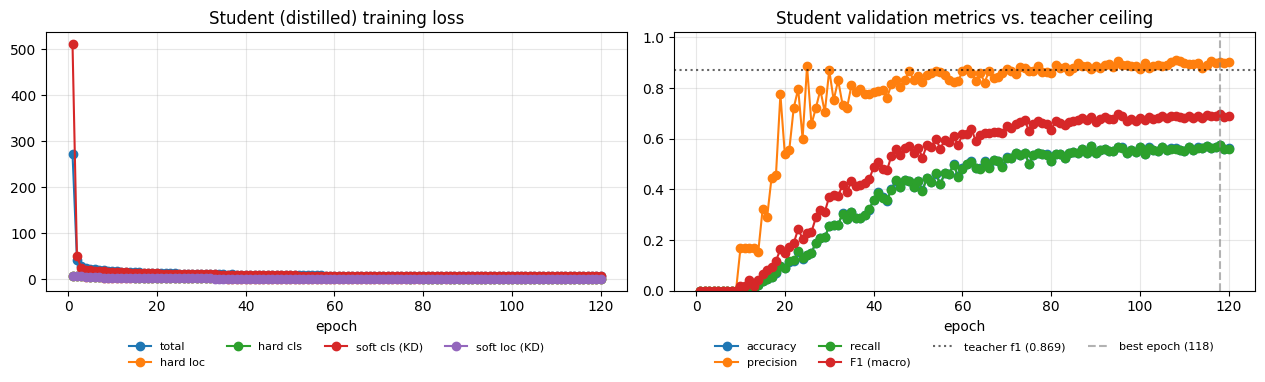

In [24]:
if student_history is None:
    print("student was loaded from an existing checkpoint this run -- no per-epoch training "
          f"curve to plot. val f1_macro = {student_best_f1:.4f}")
    print(f"teacher f1_macro: {teacher_best_f1:.4f}   student reached "
          f"{student_best_f1 / max(teacher_best_f1, 1e-8):.1%} of teacher performance")
    print("(set FORCE_RETRAIN_STUDENT = True in the cell above and rerun both cells if you "
          "need fresh training curves)")
else:
    epochs_range = range(1, len(student_history["total"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(epochs_range, student_history["total"], marker="o", label="total")
    axes[0].plot(epochs_range, student_history["loc"], marker="o", label="hard loc")
    axes[0].plot(epochs_range, student_history["cls"], marker="o", label="hard cls")
    axes[0].plot(epochs_range, student_history["soft_cls"], marker="o", label="soft cls (KD)")
    axes[0].plot(epochs_range, student_history["soft_loc"], marker="o", label="soft loc (KD)")
    axes[0].set_title("Student (distilled) training loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
    axes[0].grid(alpha=0.3)

    for key, label in [("val_accuracy", "accuracy"), ("val_precision", "precision"),
                        ("val_recall", "recall"), ("val_f1_macro", "F1 (macro)")]:
        axes[1].plot(epochs_range, student_history[key], marker="o", label=label)
    axes[1].axhline(teacher_best_f1, color="black", linestyle=":", alpha=0.6,
                      label=f"teacher f1 ({teacher_best_f1:.3f})")
    axes[1].axvline(student_best_epoch, color="gray", linestyle="--", alpha=0.6,
                     label=f"best epoch ({student_best_epoch})")
    axes[1].set_title("Student validation metrics vs. teacher ceiling")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylim(0, 1.02)
    axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
    axes[1].grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig(os.path.join(MODELS_DIR, "student_training_curves.png"), dpi=150)

    print(f"student best epoch: {student_best_epoch}   {SELECTION_METRIC} = {student_best_f1:.4f}")
    print(f"teacher {SELECTION_METRIC}: {teacher_best_f1:.4f}   "
          f"student reached {student_best_f1 / max(teacher_best_f1, 1e-8):.1%} of teacher performance "
          f"at {STUDENT_WIDTH_MULT/TEACHER_WIDTH_MULT:.0%} of the backbone width")

# `model` is what Sections 9/10 (inference, export) operate on -- the student is the actual
# deployable artifact, the teacher was only ever a training aid
model = student_model


## 9 — Inference & Simplified Post-Processing

No greedy NMS loop: the deployment target assumes at most one hand per frame, so post-processing
is a confidence threshold, then a single global argmax over all anchors to pick the one box.

In [25]:
@torch.no_grad()
def detect_single_hand(model, image_tensor, anchors_center, conf_thresh: float = 0.5):
    """
    image_tensor: (1,3,H,W). Returns the single highest-confidence detection above
    conf_thresh, or None. Single-hand assumption -> threshold, then one global argmax
    over all anchors.
    """
    model.eval()
    cls_preds, loc_preds = model(image_tensor)               # (1,A,C+1), (1,A,4)

    probs = F.softmax(cls_preds, dim=-1)
    fg_probs = probs[..., 1:]                                  # drop the background column
    best_score_per_anchor, best_cls_per_anchor = fg_probs.max(dim=-1)   # (1,A) each

    # 1) confidence threshold ...
    thresholded = best_score_per_anchor.masked_fill(best_score_per_anchor < conf_thresh, -1.0)
    # 2) ... then a single global argmax over all anchors
    best_score, best_anchor_idx = thresholded.max(dim=-1)

    if best_score.item() < 0:                                  # nothing cleared the threshold
        return None

    b = 0
    a_idx = best_anchor_idx[b].item()
    cls_id = best_cls_per_anchor[b, a_idx].item()
    score = best_score_per_anchor[b, a_idx].item()

    decoded_center = decode_boxes(loc_preds[b, a_idx], anchors_center[a_idx])
    decoded_corner = center_to_corner(decoded_center.unsqueeze(0)).squeeze(0).clamp(0.0, 1.0)

    return {
        "label_id": cls_id,
        "label_name": CLASS_NAMES[cls_id],
        "score": score,
        "box_norm": decoded_corner,          # (4,) x1,y1,x2,y2 in [0,1]
        "box_px": decoded_corner * IMG_SIZE,
        "anchor_idx": a_idx,
    }

Qualitative check — 8 validation images, predicted box (red, solid) vs. ground truth (green,
dashed). Same as `scripts/demo.py`, folded into the notebook so it reuses `model` and `val_loader`
straight from memory instead of reloading a checkpoint from disk.

rendering predictions:   0%|          | 0/8 [00:00<?, ?it/s]

detections above threshold: 5/8  (dashed green = ground truth, solid red = prediction)
saved figure to c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\demo_predictions.png


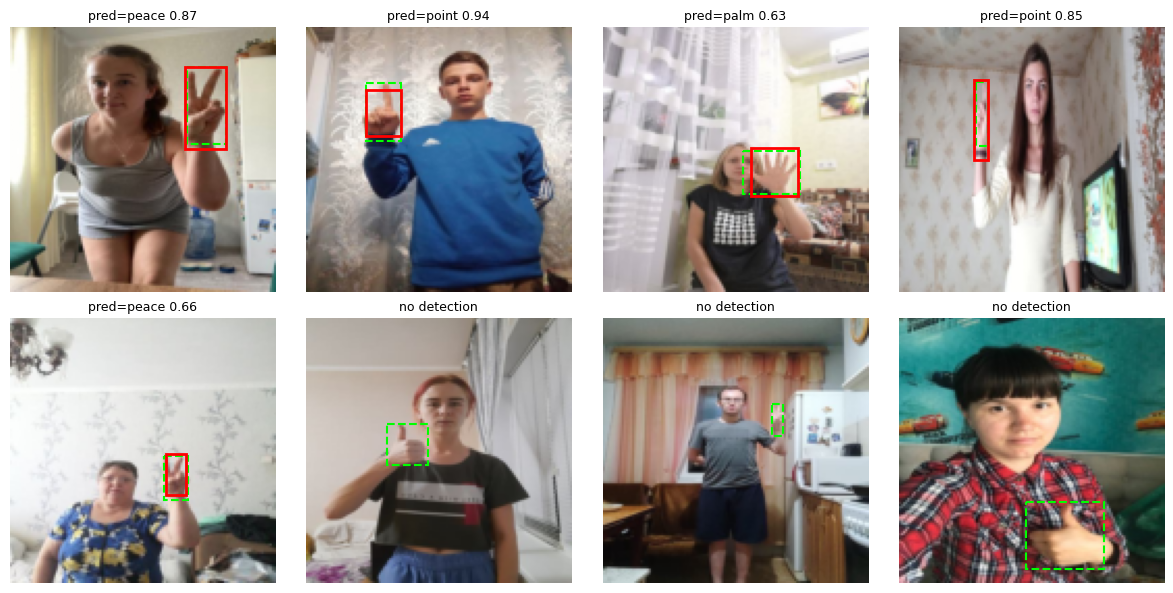

In [26]:
import matplotlib.patches as patches

val_ds = val_loader.dataset

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
n_hits = 0
for i, ax in enumerate(tqdm(axes.flat, total=8, desc="rendering predictions", leave=False)):
    img, gt_box, gt_label = val_ds[i]
    det = detect_single_hand(model, img.unsqueeze(0).to(device), anchors_center_d, conf_thresh=0.5)

    ax.imshow(img.permute(1, 2, 0).numpy())
    gx1, gy1, gx2, gy2 = (gt_box * IMG_SIZE).tolist()
    ax.add_patch(patches.Rectangle((gx1, gy1), gx2 - gx1, gy2 - gy1, fill=False,
                                    edgecolor="lime", linewidth=1.5, linestyle="--"))
    if det is not None:
        n_hits += 1
        px1, py1, px2, py2 = det["box_px"].tolist()
        ax.add_patch(patches.Rectangle((px1, py1), px2 - px1, py2 - py1, fill=False,
                                        edgecolor="red", linewidth=2))
        ax.set_title(f"pred={det['label_name']} {det['score']:.2f}", fontsize=9)
    else:
        ax.set_title("no detection", fontsize=9)
    ax.axis("off")

fig.tight_layout()
out_path = os.path.join(MODELS_DIR, "demo_predictions.png")
fig.savefig(out_path, dpi=150)
print(f"detections above threshold: {n_hits}/8  (dashed green = ground truth, solid red = prediction)")
print(f"saved figure to {out_path}")

## 10 — ONNX Export (fixed shapes) → ESP-PPQ / ESP-DL

Static shapes throughout — ESP-PPQ (and ESP-DL) expect a fixed-shape graph, so
`dynamic_axes=None` and the legacy TorchScript-based exporter (`dynamo=False`) are used
deliberately here.

In [27]:
import copy


class ONNXWrapper(nn.Module):
    """Ensures ONNX export sees exactly two plain tensor outputs."""

    def __init__(self, m):
        super().__init__()
        self.m = m

    def forward(self, x):
        cls_out, loc_out = self.m(x)
        return cls_out, loc_out


def export_to_onnx(model, onnx_path: str = None):
    onnx_path = onnx_path or os.path.join(MODELS_DIR, "gesture_ssdlite.onnx")
    # deep-copy first -- wrapping `model` directly and calling .to("cpu") on the wrapper
    # moves the ORIGINAL model's parameters in place (nn.Module.to() mutates, it doesn't
    # clone), which would silently strand your live training-session `model` on CPU.
    export_model = ONNXWrapper(copy.deepcopy(model)).to("cpu").eval()
    dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)

    torch.onnx.export(
        export_model,
        dummy_input,
        onnx_path,
        opset_version=13,
        input_names=["input"],
        output_names=["cls_logits", "loc_preds"],
        do_constant_folding=True,
        dynamic_axes=None,      # fixed shapes required for ESP-PPQ / ESP-DL
        dynamo=False,            # legacy TorchScript exporter -> static-shape graph
    )
    print("exported:", onnx_path)
    return onnx_path, export_model, dummy_input


def verify_onnx(onnx_path: str, export_model: nn.Module, dummy_input: torch.Tensor):
    import onnx
    import onnxruntime as ort

    onnx_model = onnx.load(onnx_path)
    onnx.checker.check_model(onnx_model)
    print("onnx.checker passed")

    for t in onnx_model.graph.input:
        print("input :", t.name, [d.dim_value for d in t.type.tensor_type.shape.dim])
    for t in onnx_model.graph.output:
        print("output:", t.name, [d.dim_value for d in t.type.tensor_type.shape.dim])

    # numerically verify the ONNX graph matches the PyTorch model
    sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
    ort_cls, ort_loc = sess.run(None, {"input": dummy_input.numpy()})
    with torch.no_grad():
        torch_cls, torch_loc = export_model(dummy_input)

    max_diff_cls = np.abs(ort_cls - torch_cls.numpy()).max()
    max_diff_loc = np.abs(ort_loc - torch_loc.numpy()).max()
    print(f"max abs diff -> cls: {max_diff_cls:.2e}   loc: {max_diff_loc:.2e}")
    assert np.allclose(ort_cls, torch_cls.numpy(), atol=1e-4)
    assert np.allclose(ort_loc, torch_loc.numpy(), atol=1e-4)
    print("ONNX <-> PyTorch numerical match OK")

    print(f"\n{onnx_path}: {os.path.getsize(onnx_path) / 1024:.1f} KB")

In [28]:
# export the STUDENT (the deployment target) -- the teacher only exists to train the
# student and never ships. export_model is a CPU copy; student_model itself stays on
# `device`, untouched.
onnx_path, export_model, dummy_input = export_to_onnx(student_model)
verify_onnx(onnx_path, export_model, dummy_input)

exported: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\gesture_ssdlite.onnx
onnx.checker passed
input : input [1, 3, 128, 128]
output: cls_logits [1, 128, 7]
output: loc_preds [1, 128, 4]
max abs diff -> cls: 4.29e-06   loc: 7.87e-06
ONNX <-> PyTorch numerical match OK

c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\gesture_ssdlite.onnx: 360.3 KB


## 10b -- Quantization: PTQ then QAT, one session

Post-training quantization (PTQ) and quantization-aware fine-tuning (QAT) run back to back
below as a single continuous section, not two separate passes: PTQ produces `quant_ppq_graph`
and its own float32/PTQ-INT8 comparison figures first (teacher kept in as a reference
throughout, student is the actual deployment target), then QAT fine-tunes that same graph
directly and gets an identical set of comparison figures, plus a combined summary at the end.

Requires ESP-PPQ installed once, outside the notebook:
```bash
pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu
pip install esp-ppq
```


### Next steps for on-device deployment

This notebook stops at a verified, static-shape ONNX graph, exported from the **best checkpoint by
validation macro-F1** (epoch printed in Section 8), trained on real HaGRID data with a pretrained
backbone, fitted anchors, and augmentation. To finish the pipeline:

1. **Quantize** `gesture_ssdlite.onnx` to INT8 with `esp_ppq.api.espdl_quantize_onnx` against a
   small calibration set of real frames from the HaGRID validation split used above.
2. **Update firmware constants** (`IMG_H/IMG_W/IMG_C`, buffer sizes) for 128×128×3 input, and
   replace a single-label argmax readout with logic that reads both heads (`cls_logits`,
   `loc_preds`) and applies the same threshold+argmax rule as `detect_single_hand` above.
3. **`WIDTH_MULT=1.0` is well past the ~100,000-param ESP32-class budget** the original
   anchor/head design was sized for (see `model.param_summary()` in Section 4 for the exact
   count). That's expected here — this notebook exists to test whether pretrained features fix
   convergence at all, before paying the cost of shrinking back down. If this run gets a val_f1
   worth keeping, the next step is either the KD notebook (distill this into a small from-scratch
   student) or structured pruning back toward width_mult≈0.35–0.5.
4. **If `SELECTION_METRIC` in Section 8 doesn't match your deployment priority** (e.g. you care
   more about never missing a gesture than about false positives), switch it to `"recall"` or
   `"precision"` and rerun training — everything downstream (best-checkpoint save, ONNX export)
   picks it up automatically.

In [29]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 1 of 9
# Run this LAST, after Section 10 (ONNX export of the STUDENT) and after running
# that ONNX through the ESPDL quantization pipeline below.
#
# Computes float32 baselines for BOTH models:
#   - teacher_model : never deployed, kept only as the upper-bound reference
#   - student_model : the actual deployment target (fp32, pre-quantization)
# The real on-device number is the student, quantized, computed in Cell 3.
#
# Depends on objects already in memory: teacher_model, student_model, val_loader,
# anchors_center_d, device, MODELS_DIR, evaluate, predict_batch_labels, CLASS_NAMES,
# NUM_CLASSES, IMG_SIZE
# =============================================================================

import os
import numpy as np
import torch
from sklearn.metrics import confusion_matrix


def state_dict_size_kb(m) -> float:
    import tempfile
    with tempfile.NamedTemporaryFile() as f:
        torch.save(m.state_dict(), f)
        return os.path.getsize(f.name) / 1024


@torch.no_grad()
def evaluate_with_predictions(model, loader, anchors_center, device, conf_thresh: float = 0.5):
    """Same metrics as `evaluate()`, but also returns per-sample predicted/true labels for a
    confusion matrix. A missed detection is encoded as label index NUM_CLASSES ("missed")."""
    model.eval()
    all_preds, all_gts = [], []
    for imgs, boxes, labels in loader:
        imgs_dev = imgs.to(device)
        preds = predict_batch_labels(model, imgs_dev, anchors_center, conf_thresh).cpu()
        preds = torch.where(preds == -1, torch.full_like(preds, NUM_CLASSES), preds)
        all_preds.append(preds)
        all_gts.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_gts).numpy()


def backbone_activation_sensitivity(fp32_model, X_sample: torch.Tensor):
    """Per-block estimate of how much INT8-level rounding would perturb this block's
    activations (min-max symmetric fake-quant at 8 bits). Diagnostic only, run on the
    STUDENT backbone since that's the one actually being quantized/deployed."""
    results = []
    fp32_model = fp32_model.eval().cpu()
    with torch.no_grad():
        x = X_sample.cpu()
        for idx, block in enumerate(fp32_model.backbone):
            x = block(x)
            act = x.detach().numpy().astype(np.float32)
            act_max = np.max(np.abs(act)) + 1e-8
            scale = act_max / 127.0
            act_q = np.round(act / scale).clip(-128, 127) * scale
            mse = float(np.mean((act - act_q) ** 2))
            signal_power = float(np.mean(act ** 2))
            noise_power = mse + 1e-12
            sqnr = 10 * np.log10(signal_power / noise_power) if signal_power > 0 else 0.0
            results.append({"block": idx, "type": type(block).__name__, "mse": mse, "sqnr": sqnr})
    return results


# ---- teacher fp32 (reference only, never deployed) --------------------------
print("evaluating teacher (float32, reference)...")
metrics_teacher = evaluate(teacher_model, val_loader, anchors_center_d, device)
preds_teacher, gts_teacher = evaluate_with_predictions(teacher_model, val_loader, anchors_center_d, device)
size_teacher_kb = state_dict_size_kb(teacher_model)

# ---- student fp32 (pre-quantization deployment candidate) -------------------
print("evaluating student (float32, pre-quantization)...")
metrics_fp32 = evaluate(student_model, val_loader, anchors_center_d, device)
preds_fp32, gts_fp32 = evaluate_with_predictions(student_model, val_loader, anchors_center_d, device)
size_fp32_kb = state_dict_size_kb(student_model)
layer_errors = backbone_activation_sensitivity(student_model, next(iter(val_loader))[0][:16])

print(f"\n{'Metric':<14}{'Teacher fp32':>14}{'Student fp32':>14}")
for k, label in [("accuracy", "Accuracy"), ("precision", "Precision"),
                  ("recall", "Recall"), ("f1_macro", "F1 (macro)")]:
    print(f"{label:<14}{metrics_teacher[k]*100:>13.2f}%{metrics_fp32[k]*100:>13.2f}%")
print(f"\nTeacher size (state_dict): {size_teacher_kb:8.1f} KB")
print(f"Student size (state_dict): {size_fp32_kb:8.1f} KB   ({size_teacher_kb/size_fp32_kb:.2f}x smaller than teacher)")

evaluating teacher (float32, reference)...


validating:   0%|          | 0/7 [00:00<?, ?it/s]

evaluating student (float32, pre-quantization)...


validating:   0%|          | 0/7 [00:00<?, ?it/s]


Metric          Teacher fp32  Student fp32
Accuracy              79.68%        57.51%
Precision             95.73%        90.11%
Recall                79.82%        57.42%
F1 (macro)            86.92%        69.78%

Teacher size (state_dict):   2283.5 KB
Student size (state_dict):    446.3 KB   (5.12x smaller than teacher)


In [30]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 2 of 9
# Quantize Section 10's STUDENT ONNX export into a real .espdl model via ESP-PPQ.
# The teacher is never quantized -- it doesn't deploy, it only trained the student.
# =============================================================================

from torch.utils.data import DataLoader
from esp_ppq.api import espdl_quantize_onnx

ESPDL_TARGET = "esp32s3"
ESPDL_NUM_BITS = 8
ESPDL_CALIB_STEPS = min(200, len(val_loader.dataset))
ESPDL_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ESPDL_MODEL_PATH = os.path.join(MODELS_DIR, "gesture_ssdlite.espdl")

calib_loader = DataLoader(val_loader.dataset, batch_size=1, shuffle=False)


def collate_fn(batch):
    imgs, _boxes, _labels = batch
    return imgs.to(ESPDL_DEVICE)


print(f"quantizing STUDENT to INT8 for target={ESPDL_TARGET} "
      f"({ESPDL_CALIB_STEPS} calibration steps, device={ESPDL_DEVICE})...")

quant_ppq_graph = espdl_quantize_onnx(
    onnx_import_file=onnx_path,                 # student ONNX from Section 10
    espdl_export_file=ESPDL_MODEL_PATH,
    calib_dataloader=calib_loader,
    calib_steps=ESPDL_CALIB_STEPS,
    input_shape=[1, 3, IMG_SIZE, IMG_SIZE],
    inputs=None,
    target=ESPDL_TARGET,
    num_of_bits=ESPDL_NUM_BITS,
    collate_fn=collate_fn,
    device=ESPDL_DEVICE,
    error_report=True,
    skip_export=False,
    export_test_values=True,
    verbose=1,
)

size_int8_kb = os.path.getsize(ESPDL_MODEL_PATH) / 1024
print(f"\nexported: {ESPDL_MODEL_PATH}")
print(f"on-device size: {size_int8_kb:.1f} KB")
print(f"  vs student fp32: {size_fp32_kb / size_int8_kb:.2f}x smaller")
print(f"  vs teacher fp32: {size_teacher_kb / size_int8_kb:.2f}x smaller")


    ___________ ____        ____  ____  ____
   / ____/ ___// __ \      / __ \/ __ \/ __ \
  / __/  \__ \/ /_/ /_____/ /_/ / /_/ / / / /
 / /___ ___/ / ____/_____/ ____/ ____/ /_/ /
/_____//____/_/         /_/   /_/    \___\_\


quantizing STUDENT to INT8 for target=esp32s3 (200 calibration steps, device=cuda)...
[01:29:24] ConvTranspose Decomposition Pass Running ... Finished.
[01:29:25] PPQ Quantization Fusion Pass Running ...       Finished.
[01:29:25] PPQ Quantize Simplify Pass Running ...         Finished.
[01:29:25] PPQ Parameter Quantization Pass Running ...    Finished.
[01:29:25] PPQ Runtime Calibration Pass Running ...       

Calibration Progress(Phase 2): 100%|██████████| 200/200 [00:14<00:00, 14.06it/s]


Finished.
[01:29:54] PPQ Quantization Alignment Pass Running ...    Finished.
[01:29:54] PPQ Passive Parameter Quantization Running ... Finished.
--------- Network Snapshot ---------
Num of Op:                    [85]
Num of Quantized Op:          [85]
Num of Variable:              [232]
Num of Quantized Var:         [232]
------- Quantization Snapshot ------
Num of Quant Config:          [324]
ACTIVATED:                    [87]
OVERLAPPED:                   [110]
PASSIVE:                      [123]
FP32:                         [4]
Network Quantization Finished.


Analysing Graphwise Quantization Error(Phrase 1):: 100%|██████████| 8/8 [00:01<00:00,  6.69it/s]
Analysing Graphwise Quantization Error(Phrase 2):: 100%|██████████| 8/8 [00:02<00:00,  3.04it/s]


Layer                                              | NOISE:SIGNAL POWER RATIO 
/m/backbone/backbone.6/conv/conv.2/Conv:           | ████████████████████ | 6.316%
/m/backbone/backbone.2/conv/conv.1/conv.1.0/Conv:  | █████████████████    | 5.343%
/m/backbone/backbone.3/conv/conv.1/conv.1.0/Conv:  | ███████████████      | 4.839%
/m/backbone/backbone.3/conv/conv.2/Conv:           | ███████████████      | 4.835%
/m/backbone/backbone.1/conv/conv.1/Conv:           | ███████████████      | 4.775%
/m/backbone/backbone.2/conv/conv.0/conv.0.0/Conv:  | ███████████████      | 4.725%
/m/backbone/backbone.3/conv/conv.0/conv.0.0/Conv:  | █████████████        | 4.296%
/m/backbone/backbone.6/conv/conv.1/conv.1.0/Conv:  | █████████████        | 4.287%
/m/backbone/backbone.2/conv/conv.2/Conv:           | █████████████        | 4.260%
/m/backbone/backbone.10/conv/conv.2/Conv:          | █████████████        | 4.071%
/m/backbone/backbone.5/conv/conv.2/Conv:           | █████████████        | 4.031%
/m/backb

Analysing Layerwise quantization error:: 100%|██████████| 43/43 [00:17<00:00,  2.50it/s]


Layer                                              | NOISE:SIGNAL POWER RATIO 
/m/backbone/backbone.0/backbone.0.0/Conv:          | ████████████████████ | 0.283%
/m/backbone/backbone.1/conv/conv.0/conv.0.0/Conv:  | ██████████████       | 0.202%
/m/loc_head/pointwise/Conv:                        | ██                   | 0.024%
/m/backbone/backbone.11/conv/conv.2/Conv:          | █                    | 0.019%
/m/backbone/backbone.12/conv/conv.1/conv.1.0/Conv: | █                    | 0.017%
/m/backbone/backbone.2/conv/conv.1/conv.1.0/Conv:  | █                    | 0.017%
/m/backbone/backbone.9/conv/conv.2/Conv:           | █                    | 0.013%
/m/backbone/backbone.13/conv/conv.2/Conv:          | █                    | 0.012%
/m/backbone/backbone.2/conv/conv.2/Conv:           | █                    | 0.012%
/m/backbone/backbone.4/conv/conv.2/Conv:           | █                    | 0.012%
/m/backbone/backbone.7/conv/conv.2/Conv:           | █                    | 0.010%
/m/backb

In [31]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 3 of 9
# Runs the ACTUAL quantized STUDENT graph via ESP-PPQ's TorchExecutor -- numerically
# aligned with on-chip ESP-DL inference, per Espressif's docs.
# =============================================================================

from esp_ppq.executor import TorchExecutor
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

executor = TorchExecutor(graph=quant_ppq_graph, device=ESPDL_DEVICE)


@torch.no_grad()
def evaluate_espdl(executor, dataset, anchors_center, device, conf_thresh: float = 0.5):
    all_preds, all_gts = [], []
    for img, box, label in dataset:
        img_in = img.unsqueeze(0).to(device)
        outputs = executor(img_in)
        cls_out, loc_out = outputs[0], outputs[1]

        probs = F.softmax(cls_out.float(), dim=-1)
        fg_probs = probs[..., 1:]
        best_score, best_cls = fg_probs.max(dim=-1)
        thresholded = best_score.masked_fill(best_score < conf_thresh, -1.0)
        top_score, top_anchor = thresholded.max(dim=-1)
        pred_cls = best_cls.gather(1, top_anchor.unsqueeze(1)).squeeze(1)
        pred_label = int(pred_cls.item()) if top_score.item() >= 0 else NUM_CLASSES

        all_preds.append(pred_label)
        all_gts.append(int(label))

    all_preds = np.array(all_preds)
    all_gts = np.array(all_gts)
    accuracy = accuracy_score(all_gts, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_gts, all_preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)
    n_missed = int((all_preds == NUM_CLASSES).sum())
    return ({"accuracy": accuracy, "precision": precision, "recall": recall,
             "f1_macro": f1, "n_missed": n_missed, "n_total": len(all_gts)},
            all_preds, all_gts)


print(f"running quantized STUDENT graph over {len(val_loader.dataset)} validation samples "
      f"(batch_size=1, on-device-equivalent)...")

metrics_int8, preds_int8, gts_int8 = evaluate_espdl(
    executor, val_loader.dataset, anchors_center_d, ESPDL_DEVICE)

print(f"\n{'Metric':<14}{'Teacher fp32':>14}{'Student fp32':>14}{'Student INT8':>14}")
for k, label in [("accuracy", "Accuracy"), ("precision", "Precision"),
                  ("recall", "Recall"), ("f1_macro", "F1 (macro)")]:
    t, s, q = metrics_teacher[k], metrics_fp32[k], metrics_int8[k]
    print(f"{label:<14}{t*100:>13.2f}%{s*100:>13.2f}%{q*100:>13.2f}%")
print(f"\nTeacher fp32:  {size_teacher_kb:8.1f} KB")
print(f"Student fp32:  {size_fp32_kb:8.1f} KB")
print(f"Student INT8:  {size_int8_kb:8.1f} KB")

running quantized STUDENT graph over 433 validation samples (batch_size=1, on-device-equivalent)...

Metric          Teacher fp32  Student fp32  Student INT8
Accuracy              79.68%        57.51%        56.12%
Precision             95.73%        90.11%        87.66%
Recall                79.82%        57.42%        56.04%
F1 (macro)            86.92%        69.78%        67.88%

Teacher fp32:    2283.5 KB
Student fp32:     446.3 KB
Student INT8:     233.0 KB


In [32]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 4 of 9
# Shared paper-style plotting setup.
# =============================================================================

import matplotlib.pyplot as plt

PAPER_STYLE = {
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#333333",
    "axes.labelcolor": "#111111", "axes.titlesize": 12, "axes.labelsize": 11,
    "xtick.color": "#333333", "ytick.color": "#333333", "xtick.labelsize": 9,
    "ytick.labelsize": 9, "legend.fontsize": 9, "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "grid.color": "#dddddd",
    "grid.linewidth": 0.6, "savefig.dpi": 300, "savefig.bbox": "tight",
}
plt.rcParams.update(PAPER_STYLE)

C_TEACHER = "#0072B2"   # blue
C_FP32 = "#009E73"      # bluish green (student, fp32)
C_INT8 = "#D55E00"      # vermillion (student, INT8/deployed)


def save_fig(fig, name):
    path = os.path.join(MODELS_DIR, name)
    fig.savefig(path)
    print(f"saved: {path}")

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig1_metrics_teacher_vs_student_fp32_vs_int8.png


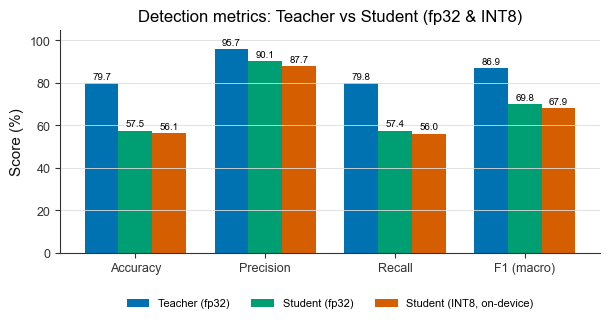

In [33]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 5 of 9
# Figure 1: Accuracy / Precision / Recall / F1 -- Teacher fp32 vs Student fp32
# vs Student INT8 (real, on-device)
# =============================================================================

fig, ax = plt.subplots(figsize=(6.2, 3.4))
labels = ["Accuracy", "Precision", "Recall", "F1 (macro)"]
keys = ["accuracy", "precision", "recall", "f1_macro"]
teacher_vals = [metrics_teacher[k] * 100 for k in keys]
fp32_vals = [metrics_fp32[k] * 100 for k in keys]
int8_vals = [metrics_int8[k] * 100 for k in keys]

x = np.arange(len(labels))
w = 0.26
b1 = ax.bar(x - w, teacher_vals, w, label="Teacher (fp32)", color=C_TEACHER)
b2 = ax.bar(x, fp32_vals, w, label="Student (fp32)", color=C_FP32)
b3 = ax.bar(x + w, int8_vals, w, label="Student (INT8, on-device)", color=C_INT8)

for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 1, f"{h:.1f}", ha="center",
                va="bottom", fontsize=7)

ax.set_ylim(0, 105)
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title("Detection metrics: Teacher vs Student (fp32 & INT8)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
ax.grid(axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig1_metrics_teacher_vs_student_fp32_vs_int8.png")
plt.show()

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig2_model_size_teacher_vs_student.png


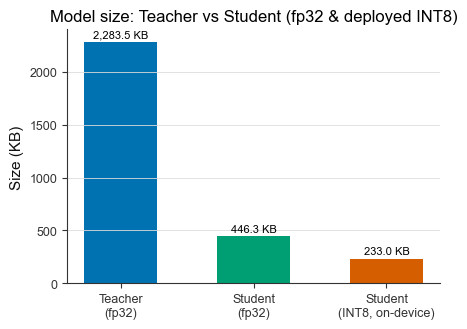

In [34]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 6 of 9
# Figure 2: model size -- Teacher (fp32) vs Student (fp32) vs Student (INT8, deployed)
# =============================================================================

fig, ax = plt.subplots(figsize=(4.6, 3.4))
sizes = [size_teacher_kb, size_fp32_kb, size_int8_kb]
tick_labels = ["Teacher\n(fp32)", "Student\n(fp32)", "Student\n(INT8, on-device)"]
colors = [C_TEACHER, C_FP32, C_INT8]

bars = ax.bar(tick_labels, sizes, color=colors, width=0.55)
for bar, val in zip(bars, sizes):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(sizes) * 0.01,
            f"{val:,.1f} KB", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Size (KB)")
ax.set_title("Model size: Teacher vs Student (fp32 & deployed INT8)")
ax.grid(axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig2_model_size_teacher_vs_student.png")
plt.show()

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig3_confusion_teacher_fp32.png


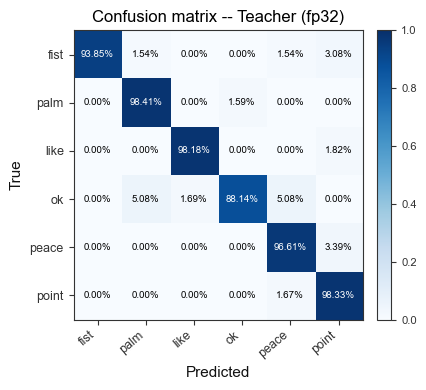

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig4_confusion_student_fp32.png


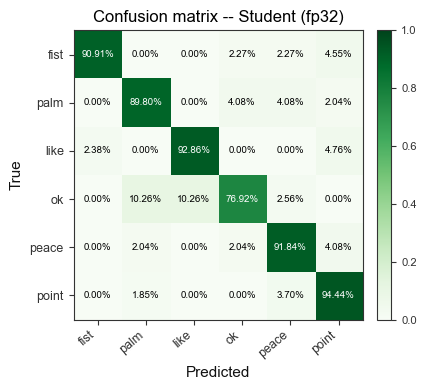

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig5_confusion_student_int8.png


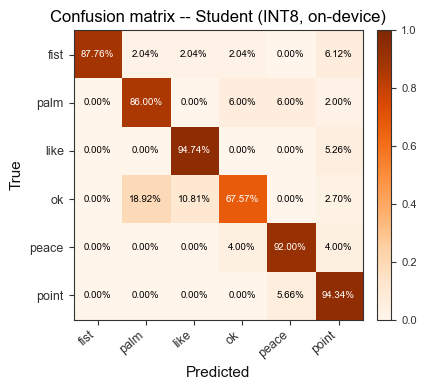

In [35]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 7 of 9
# Confusion matrices: Teacher fp32, Student fp32, Student INT8 (on-device)
# =============================================================================

from sklearn.metrics import confusion_matrix

cm_labels = CLASS_NAMES


def plot_confusion(preds, gts, title, filename, cmap):
    cm = confusion_matrix(gts, preds, labels=list(range(NUM_CLASSES)), normalize="true")
    fig, ax = plt.subplots(figsize=(4.6, 4.0))
    im = ax.imshow(cm, cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(len(cm_labels)))
    ax.set_yticks(range(len(cm_labels)))
    ax.set_xticklabels(cm_labels, rotation=40, ha="right")
    ax.set_yticklabels(cm_labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            v = cm[i, j]
            ax.text(j, i, f"{v*100:.2f}%", ha="center", va="center",
                    color="white" if v > 0.5 else "black", fontsize=7)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.tick_params(labelsize=8)
    fig.tight_layout()
    save_fig(fig, filename)
    plt.show()


plot_confusion(preds_teacher, gts_teacher, "Confusion matrix -- Teacher (fp32)",
               "fig3_confusion_teacher_fp32.png", "Blues")
plot_confusion(preds_fp32, gts_fp32, "Confusion matrix -- Student (fp32)",
               "fig4_confusion_student_fp32.png", "Greens")
plot_confusion(preds_int8, gts_int8, "Confusion matrix -- Student (INT8, on-device)",
               "fig5_confusion_student_int8.png", "Oranges")

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig6_student_backbone_sqnr.png


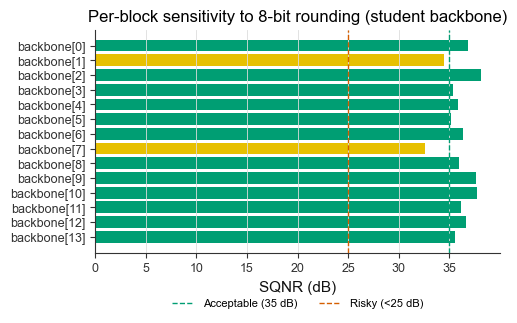

In [36]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 8 of 9
# Figure: per-block activation SQNR, STUDENT backbone (the deployed model)
# =============================================================================

fig, ax = plt.subplots(figsize=(5.2, 3.4))
block_names = [f"backbone[{r['block']}]" for r in layer_errors]
sqnrs = [min(r["sqnr"], 60) for r in layer_errors]
colors_sqnr = [C_FP32 if s >= 35 else "#E7C000" if s >= 25 else C_INT8 for s in sqnrs]

ax.barh(block_names, sqnrs, color=colors_sqnr)
ax.axvline(35, color=C_FP32, linestyle="--", linewidth=1, label="Acceptable (35 dB)")
ax.axvline(25, color=C_INT8, linestyle="--", linewidth=1, label="Risky (<25 dB)")
ax.set_xlabel("SQNR (dB)")
ax.set_title("Per-block sensitivity to 8-bit rounding (student backbone)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
ax.grid(axis="x")
ax.spines[["top", "right"]].set_visible(False)
ax.invert_yaxis()
fig.tight_layout()
save_fig(fig, "fig6_student_backbone_sqnr.png")
plt.show()

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig6_student_backbone_mse.png


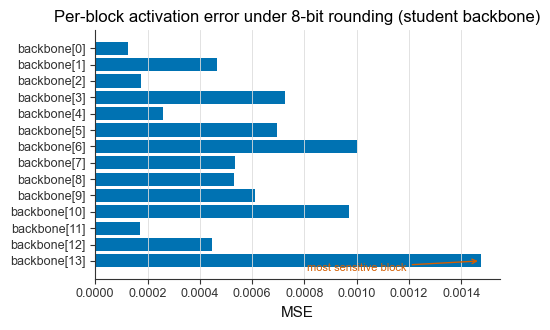

In [37]:
# =============================================================================
# POST-QUANTIZATION ANALYSIS -- CELL 9 of 9
# Figure: per-block activation MSE, STUDENT backbone
# =============================================================================

fig, ax = plt.subplots(figsize=(5.2, 3.4))
mses = [r["mse"] for r in layer_errors]
ax.barh(block_names, mses, color=C_TEACHER)
ax.set_xlabel("MSE")
ax.set_title("Per-block activation error under 8-bit rounding (student backbone)")
ax.grid(axis="x")
ax.spines[["top", "right"]].set_visible(False)
ax.invert_yaxis()
worst = int(np.argmax(mses))
ax.annotate("most sensitive block", xy=(mses[worst], worst),
            xytext=(mses[worst] * 0.55, worst + 0.6),
            fontsize=8, color=C_INT8,
            arrowprops=dict(arrowstyle="->", color=C_INT8))
fig.tight_layout()
save_fig(fig, "fig6_student_backbone_mse.png")
plt.show()

In [38]:
IMG_SIZE = 128         
STRIDE = 16
GRID_SIZE = 8
ASPECT_RATIOS = (1.0, 1.8)   
NUM_ANCHORS_PER_CELL = 2   
NUM_TOTAL_ANCHORS = 128
CLASS_NAMES = ["fist", "palm", "like", "ok", "peace", "point"]   
NUM_CLASSES = 6
BATCH_SIZE = 64
TEACHER_WIDTH_MULT = 1.0
STUDENT_WIDTH_MULT = 0.3
QAT_EPOCHS = 10 
QAT_LR = 1e-6 
QAT_MOMENTUM = 0.937 
QAT_WEIGHT_DECAY = 5e-4

### QAT -- continuing the same quantization session

Fine-tunes the PTQ-quantized graph from Section 10's post-quantization analysis
directly (ESP-PPQ `TrainableGraph` + `forward_with_gradient`, the same mechanism
ESP-DL's own QAT examples use), then compares Float32 / PTQ-INT8 / QAT-INT8.

In [39]:
from esp_ppq.IR import TrainableGraph
from esp_ppq.core import TargetPlatform
import esp_ppq.lib as PFL
from esp_ppq.parser import NativeExporter

QAT_EPOCHS = 10
QAT_LR = 1e-6
QAT_MOMENTUM = 0.937
QAT_WEIGHT_DECAY = 5e-4


class QATTrainer:
    """Adaptation of ESP-DL's own QAT Trainer (quantize_yolo11n-pose/trainer.py) to this
    project's MultiBoxLoss + anchor-matching pipeline instead of the Ultralytics pose loss.

    NOTE ON BATCH SIZE: `graph` comes from `espdl_quantize_onnx`, which quantized a
    statically-shaped ONNX export (batch=1 baked into every Reshape op -- Section 10 uses
    `dynamic_axes=None`, which ESP-DL requires). `forward_with_gradient` on this graph only
    accepts batch=1 input; feeding it a BATCH_SIZE=64 tensor throws a Reshape shape mismatch
    (target shape has a literal `1` where the input actually has 64x that many elements).

    QATTrainer therefore runs one sample at a time through the graph and accumulates
    gradients over `accum_steps` samples before each optimizer.step(), so the effective
    batch size and the number of optimizer steps per epoch match a real batch=accum_steps
    run -- only the forward/backward calls are serialized per-sample instead of batched.
    """

    def __init__(self, graph, device: str, accum_steps: int = BATCH_SIZE):
        self._epoch = 0
        self._device = device
        self._executor = TorchExecutor(graph, device=device)
        self._training_graph = TrainableGraph(graph)
        self.graph = graph
        self.accum_steps = accum_steps

        for tensor in self._training_graph.parameters():
            tensor.requires_grad = True

        self._optimizer = torch.optim.SGD(
            params=[{"params": self._training_graph.parameters()}],
            lr=QAT_LR, momentum=QAT_MOMENTUM, weight_decay=QAT_WEIGHT_DECAY)
        self.criterion = MultiBoxLoss().to(device)

    def _step(self, imgs, boxes, labels, anchors_center, anchors_corner):
        """Single-sample (batch=1) forward/backward. Loss is pre-divided by accum_steps so
        the gradient accumulated over a full pseudo-batch matches what a real batch=accum_steps
        forward with mean-reduced loss would produce."""
        imgs = imgs.to(self._device)
        boxes = boxes.to(self._device)
        labels = labels.to(self._device)

        # forward_with_gradient keeps the fake-quant ops differentiable (STE), unlike the
        # plain executor(...) inference call used for eval in the PTQ cells above.
        graph_outputs = self._executor.forward_with_gradient(imgs)
        cls_preds, loc_preds = graph_outputs[0], graph_outputs[1]   # matches ONNX output order

        cls_t, loc_t, pos_m, ign_m = match_anchors_to_targets(boxes, labels, anchors_center, anchors_corner)
        total_loss, loc_loss, cls_loss = self.criterion(cls_preds, loc_preds, cls_t, loc_t, pos_m, ign_m)

        (total_loss / self.accum_steps).backward()
        return total_loss.item()

    def epoch(self, loader, anchors_center, anchors_corner):
        """`loader` must yield batch=1 samples -- see QAT_LOADER in the cell below. Gradient
        accumulation over `accum_steps` samples restores the original effective batch size."""
        running = 0.0
        n = len(loader)
        self._training_graph.zero_grad()
        for i, (imgs, boxes, labels) in enumerate(
                tqdm(loader, desc=f"QAT epoch {self._epoch + 1}/{QAT_EPOCHS}", leave=False), start=1):
            running += self._step(imgs, boxes, labels, anchors_center, anchors_corner)
            if i % self.accum_steps == 0 or i == n:
                torch.nn.utils.clip_grad_norm_(self._training_graph.parameters(), max_norm=5.0)
                self._optimizer.step()
                self._training_graph.zero_grad()
        self._epoch += 1
        return running / n

    @torch.no_grad()
    def eval(self, val_dataset, anchors_center):
        return evaluate_espdl(self._executor, val_dataset, anchors_center, self._device)

    def save(self, espdl_path: str, native_path: str):
        PFL.Exporter(platform=TargetPlatform.ESPDL_INT8).export(file_path=espdl_path, graph=self.graph)
        NativeExporter().export(file_path=native_path, graph=self.graph)


In [40]:
# =============================================================================
# QUANTIZATION-AWARE TRAINING (QAT) -- CELL 2 of 5
# Runs QAT_EPOCHS of fine-tuning directly on `quant_ppq_graph` (the PTQ graph from the
# earlier cell), saving the best checkpoint by val f1_macro. `metrics_int8` (the pre-QAT
# PTQ result) is the baseline this is trying to beat -- QAT only "wins" if it does.
#
# Checks for a cached result first (models_kd/qat_result_cache.json + saved preds/gts) and
# loads that instead of re-running QAT_EPOCHS of fine-tuning, the same "carry on from the
# best model" pattern already used for the teacher/student checkpoints in Sections 8a/8b.
# Set FORCE_RETRAIN_QAT = True to force a fresh QAT run regardless of what's cached.
# =============================================================================

from torch.utils.data import DataLoader
import numpy as np
import json

FORCE_RETRAIN_QAT = False   # set True to always re-run QAT_EPOCHS even if a cached result exists

QAT_ACCUM_STEPS = BATCH_SIZE   # restores the original effective batch size via gradient
                                # accumulation -- see the QATTrainer docstring above for why
                                # batch=1 is mandatory at the per-sample forward level.
QAT_ESPDL_PATH = os.path.join(MODELS_DIR, "gesture_ssdlite_qat.espdl")
QAT_NATIVE_PATH = os.path.join(MODELS_DIR, "gesture_ssdlite_qat.native")
QAT_CACHE_PATH = os.path.join(MODELS_DIR, "qat_result_cache.json")
QAT_PREDS_PATH = os.path.join(MODELS_DIR, "qat_preds.npy")
QAT_GTS_PATH = os.path.join(MODELS_DIR, "qat_gts.npy")

if not FORCE_RETRAIN_QAT and os.path.exists(QAT_CACHE_PATH) and os.path.exists(QAT_PREDS_PATH):
    print(f"found cached QAT result: {QAT_CACHE_PATH}")
    print("loading instead of retraining (set FORCE_RETRAIN_QAT = True above to force a fresh run)")
    with open(QAT_CACHE_PATH) as f:
        _cache = json.load(f)
    best_qat_f1 = _cache["best_qat_f1"]
    best_qat_epoch = _cache["best_qat_epoch"]
    best_qat_metrics = _cache["best_qat_metrics"]
    size_qat_kb = _cache["size_qat_kb"]
    best_qat_preds = np.load(QAT_PREDS_PATH)
    best_qat_gts = np.load(QAT_GTS_PATH)
    print(f"loaded. best QAT epoch={best_qat_epoch}  f1_macro={best_qat_f1:.4f}  size={size_qat_kb:.1f} KB")
else:
    qat_loader = DataLoader(train_loader.dataset, batch_size=1, shuffle=True)
    qat_trainer = QATTrainer(quant_ppq_graph, device=ESPDL_DEVICE, accum_steps=QAT_ACCUM_STEPS)

    best_qat_f1 = metrics_int8["f1_macro"]
    best_qat_epoch = 0
    # default to the PTQ result -- keeps every downstream comparison cell well-defined even on
    # a run where QAT never beats PTQ (the two bars will just come out identical, which is itself
    # a valid, reportable result).
    best_qat_metrics, best_qat_preds, best_qat_gts = metrics_int8, preds_int8, gts_int8
    print(f"pre-QAT (PTQ) baseline: f1_macro={best_qat_f1:.4f}")

    for epoch in range(1, QAT_EPOCHS + 1):
        train_loss = qat_trainer.epoch(qat_loader, anchors_center_d, anchors_corner_d)
        epoch_metrics, epoch_preds, epoch_gts = qat_trainer.eval(val_loader.dataset, anchors_center_d)

        is_best = epoch_metrics["f1_macro"] > best_qat_f1
        if is_best:
            best_qat_f1 = epoch_metrics["f1_macro"]
            best_qat_epoch = epoch
            best_qat_metrics, best_qat_preds, best_qat_gts = epoch_metrics, epoch_preds, epoch_gts
            qat_trainer.save(QAT_ESPDL_PATH, QAT_NATIVE_PATH)

        print(f"QAT epoch {epoch}/{QAT_EPOCHS}  train_loss={train_loss:.4f}  "
              f"val_f1={epoch_metrics['f1_macro']:.4f}  val_acc={epoch_metrics['accuracy']:.4f}"
              f"{'  <-- best so far, saved' if is_best else ''}")

    print(f"\nbest QAT checkpoint: epoch {best_qat_epoch}  f1_macro={best_qat_f1:.4f}")
    if best_qat_epoch == 0:
        print("QAT never beat the plain PTQ baseline -- no .espdl/.native was saved this run. "
              "The comparison cells below will show PTQ and QAT as identical bars, since "
              "best_qat_* falls back to the PTQ result. Consider more QAT_EPOCHS, a different "
              "QAT_LR, or check for early overfitting.")

    # same INT8 architecture and quantization scheme as PTQ -- weights differ, op graph and byte
    # layout don't. Measure the real saved file when QAT actually produced one, otherwise the
    # size is exactly the PTQ size by construction.
    if best_qat_epoch > 0 and os.path.exists(QAT_ESPDL_PATH):
        size_qat_kb = os.path.getsize(QAT_ESPDL_PATH) / 1024
    else:
        size_qat_kb = size_int8_kb

    # cache to disk so the next run can skip straight to the comparison cells
    with open(QAT_CACHE_PATH, "w") as f:
        json.dump({"best_qat_f1": best_qat_f1, "best_qat_epoch": best_qat_epoch,
                    "best_qat_metrics": {k: float(v) for k, v in best_qat_metrics.items()},
                    "size_qat_kb": size_qat_kb}, f, indent=2)
    np.save(QAT_PREDS_PATH, np.asarray(best_qat_preds))
    np.save(QAT_GTS_PATH, np.asarray(best_qat_gts))
    print(f"cached QAT result -> {QAT_CACHE_PATH}")


pre-QAT (PTQ) baseline: f1_macro=0.6788


QAT epoch 1/10:   0%|          | 0/3906 [00:00<?, ?it/s]

QAT epoch 1/10  train_loss=3.0363  val_f1=0.6730  val_acc=0.5497


QAT epoch 2/10:   0%|          | 0/3906 [00:00<?, ?it/s]

QAT epoch 2/10  train_loss=3.0266  val_f1=0.6752  val_acc=0.5497


...

QAT epoch 8/10  train_loss=2.9263  val_f1=0.6912  val_acc=0.5681


QAT epoch 9/10:   0%|          | 0/3906 [00:00<?, ?it/s]

QAT epoch 9/10  train_loss=2.9894  val_f1=0.6813  val_acc=0.5589


QAT epoch 10/10:   0%|          | 0/3906 [00:00<?, ?it/s]

QAT epoch 10/10  train_loss=2.9142  val_f1=0.6875  val_acc=0.5635

best QAT checkpoint: epoch 6  f1_macro=0.6920
cached QAT result -> c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\qat_result_cache.json


### 11a -- Float32 / PTQ-INT8 / QAT-INT8 comparison

Same figures as Section 10's post-quantization analysis (`fig1`-`fig6`), extended with the
QAT-INT8 result (`best_qat_metrics`, `best_qat_preds`, `best_qat_gts`, `size_qat_kb` from the
cell above). Teacher fp32 is kept as the upper-bound reference; Student fp32 -> PTQ-INT8 ->
QAT-INT8 is the actual deployment path this section evaluates.

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig7_metrics_fp32_vs_ptq_vs_qat.png


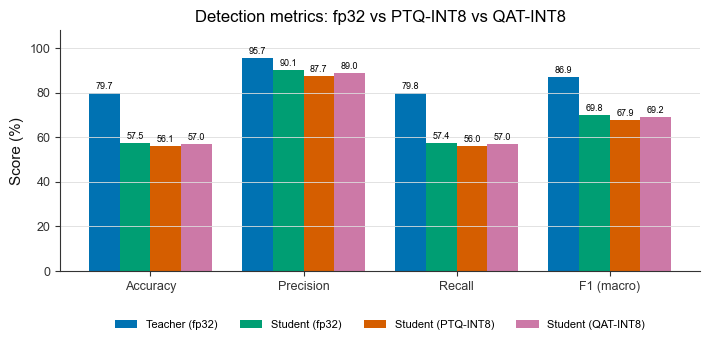

In [41]:
# =============================================================================
# QUANTIZATION-AWARE TRAINING (QAT) -- CELL 3 of 5
# Figure 7: Accuracy / Precision / Recall / F1 -- fp32 vs PTQ-INT8 vs QAT-INT8
# (four-way: Teacher fp32 kept as reference, Student fp32/PTQ/QAT is the real comparison)
# =============================================================================

C_QAT = "#CC79A7"  # reddish purple, next in the same colorblind-safe (Okabe-Ito) family
                    # as C_TEACHER/C_FP32/C_INT8 above

fig, ax = plt.subplots(figsize=(7.2, 3.6))
labels = ["Accuracy", "Precision", "Recall", "F1 (macro)"]
keys = ["accuracy", "precision", "recall", "f1_macro"]
teacher_vals = [metrics_teacher[k] * 100 for k in keys]
fp32_vals = [metrics_fp32[k] * 100 for k in keys]
ptq_vals = [metrics_int8[k] * 100 for k in keys]
qat_vals = [best_qat_metrics[k] * 100 for k in keys]

x = np.arange(len(labels))
w = 0.2
b1 = ax.bar(x - 1.5 * w, teacher_vals, w, label="Teacher (fp32)", color=C_TEACHER)
b2 = ax.bar(x - 0.5 * w, fp32_vals, w, label="Student (fp32)", color=C_FP32)
b3 = ax.bar(x + 0.5 * w, ptq_vals, w, label="Student (PTQ-INT8)", color=C_INT8)
b4 = ax.bar(x + 1.5 * w, qat_vals, w, label="Student (QAT-INT8)", color=C_QAT)

for bars in (b1, b2, b3, b4):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 1, f"{h:.1f}", ha="center",
                va="bottom", fontsize=6.5)

ax.set_ylim(0, 108)
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title("Detection metrics: fp32 vs PTQ-INT8 vs QAT-INT8")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
ax.grid(axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig7_metrics_fp32_vs_ptq_vs_qat.png")
plt.show()


saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig8_model_size_fp32_vs_ptq_vs_qat.png


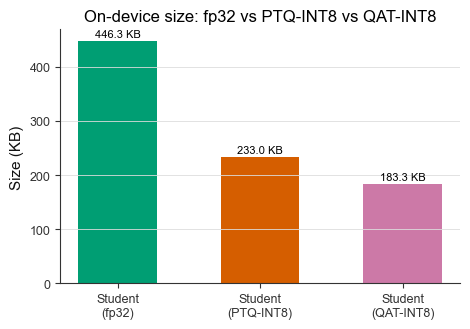

In [42]:
# =============================================================================
# QUANTIZATION-AWARE TRAINING (QAT) -- CELL 4 of 5
# Figure 8: on-device size -- Student fp32 vs PTQ-INT8 vs QAT-INT8
# (PTQ and QAT share the same op graph and INT8 byte layout, so these two bars are expected
# to be equal or near-equal -- QAT changes weight VALUES, not model SIZE)
# =============================================================================

fig, ax = plt.subplots(figsize=(4.8, 3.4))
sizes = [size_fp32_kb, size_int8_kb, size_qat_kb]
tick_labels = ["Student\n(fp32)", "Student\n(PTQ-INT8)", "Student\n(QAT-INT8)"]
colors = [C_FP32, C_INT8, C_QAT]

bars = ax.bar(tick_labels, sizes, color=colors, width=0.55)
for bar, val in zip(bars, sizes):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(sizes) * 0.01,
            f"{val:,.1f} KB", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Size (KB)")
ax.set_title("On-device size: fp32 vs PTQ-INT8 vs QAT-INT8")
ax.grid(axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig8_model_size_fp32_vs_ptq_vs_qat.png")
plt.show()


saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig9_confusion_student_qat.png


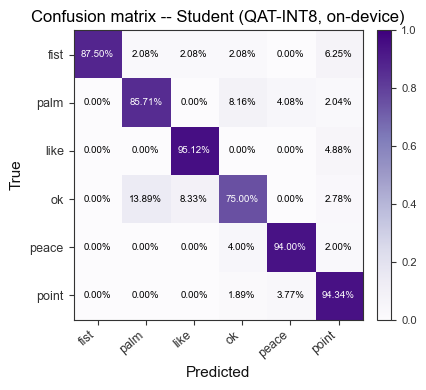

In [43]:
# =============================================================================
# QUANTIZATION-AWARE TRAINING (QAT) -- CELL 5 of 5
# Figure 9: confusion matrix -- Student QAT-INT8 (compare directly against fig5,
# Student PTQ-INT8, from Section 10)
# =============================================================================

plot_confusion(best_qat_preds, best_qat_gts, "Confusion matrix -- Student (QAT-INT8, on-device)",
               "fig9_confusion_student_qat.png", "Purples")


In [44]:
# =============================================================================
# Research-grade summary table: fp32 / PTQ-INT8 / QAT-INT8, ready for the paper.
# Prints to stdout and writes a LaTeX table (booktabs-style via pandas.to_latex) to
# MODELS_DIR/table_fp32_ptq_qat_comparison.tex for direct \input{} into the ISAIA writeup.
# =============================================================================

import pandas as pd

metric_keys = ["accuracy", "precision", "recall", "f1_macro"]
metric_labels = {"accuracy": "Accuracy (%)", "precision": "Precision (%)",
                  "recall": "Recall (%)", "f1_macro": "F1 macro (%)"}

rows = [
    {"Model": "Teacher (fp32)", "Size (KB)": size_teacher_kb,
     **{metric_labels[k]: metrics_teacher[k] * 100 for k in metric_keys}},
    {"Model": "Student (fp32)", "Size (KB)": size_fp32_kb,
     **{metric_labels[k]: metrics_fp32[k] * 100 for k in metric_keys}},
    {"Model": "Student (PTQ-INT8)", "Size (KB)": size_int8_kb,
     **{metric_labels[k]: metrics_int8[k] * 100 for k in metric_keys}},
    {"Model": "Student (QAT-INT8)", "Size (KB)": size_qat_kb,
     **{metric_labels[k]: best_qat_metrics[k] * 100 for k in metric_keys}},
]
df_comparison = pd.DataFrame(rows).set_index("Model").round(2)
print(df_comparison.to_string())

qat_vs_ptq_delta = best_qat_metrics["f1_macro"] - metrics_int8["f1_macro"]
fp32_vs_ptq_drop = metrics_fp32["f1_macro"] - metrics_int8["f1_macro"]
fp32_vs_qat_drop = metrics_fp32["f1_macro"] - best_qat_metrics["f1_macro"]
recovered_pct = (100 * qat_vs_ptq_delta / fp32_vs_ptq_drop) if fp32_vs_ptq_drop > 0 else float("nan")

print(f"\nfp32 -> PTQ-INT8 macro-F1 drop:  {fp32_vs_ptq_drop*100:+.2f} points")
print(f"fp32 -> QAT-INT8 macro-F1 drop:  {fp32_vs_qat_drop*100:+.2f} points")
print(f"QAT vs PTQ macro-F1 delta:       {qat_vs_ptq_delta*100:+.2f} points"
      f"{f'  (recovered {recovered_pct:.0f}% of the PTQ quantization drop)' if fp32_vs_ptq_drop > 0 else ''}")

latex_path = os.path.join(MODELS_DIR, "table_fp32_ptq_qat_comparison.tex")
with open(latex_path, "w") as f:
    f.write(df_comparison.to_latex(
        float_format="%.2f",
        caption="Detection metrics and on-device size across float32, PTQ-INT8, and "
                "QAT-INT8 variants of the TinyGestureSSD student.",
        label="tab:qat_comparison",
    ))
print(f"\nsaved LaTeX table: {latex_path}")


                    Size (KB)  Accuracy (%)  Precision (%)  Recall (%)  F1 macro (%)
Model                                                                               
Teacher (fp32)        2283.50         79.68          95.73       79.82         86.92
Student (fp32)         446.31         57.51          90.11       57.42         69.78
Student (PTQ-INT8)     232.98         56.12          87.66       56.04         67.88
Student (QAT-INT8)     183.31         57.04          88.95       57.00         69.20

fp32 -> PTQ-INT8 macro-F1 drop:  +1.90 points
fp32 -> QAT-INT8 macro-F1 drop:  +0.59 points
QAT vs PTQ macro-F1 delta:       +1.32 points  (recovered 69% of the PTQ quantization drop)

saved LaTeX table: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\table_fp32_ptq_qat_comparison.tex


## 12 -- width_mult Pareto Sweep

Backlog item from the wider case-study plan (Youcef confirmed, "nc"). Trains + distills a
fresh student at each width in `SWEEP_WIDTHS`, quantizes each to INT8 the same way as Section
10/11a, and plots F1 vs param count and F1 vs `.espdl` size -- so the choice of
`STUDENT_WIDTH_MULT=0.3` is justified by a curve instead of a footnote, per the backlog note.

Reuses `train_model_kd`, `export_to_onnx`, `espdl_quantize_onnx`, and `evaluate_espdl` exactly
as defined in Sections 8b/10/11 -- no new training or quantization logic, just looped.

In [45]:
# =============================================================================
# WIDTH_MULT PARETO SWEEP -- CELL 1 of 3
# width_mult=STUDENT_WIDTH_MULT (0.3) is NOT retrained here -- it already has a full PTQ
# result in memory (student_model / metrics_int8 / size_int8_kb from Sections 8b/10/11), so
# that point is reused rather than duplicating a ~180-epoch training run.
# =============================================================================

SWEEP_WIDTHS = [0.25, 0.5, 0.75]   # STUDENT_WIDTH_MULT (0.3) folded back in below. Widths chosen
                                    # to overlap with the standard notebook's scratch sweep
                                    # ([0.25, 0.5, 0.75, 1.0]) so scratch-vs-KD can be compared
                                    # at matching widths -- 1.0 excluded here since a KD student
                                    # at the teacher's own width isn't a meaningful compression point.
SWEEP_DIR = os.path.join(PROJECT_ROOT, "models_width_sweep")
os.makedirs(SWEEP_DIR, exist_ok=True)

sweep_calib_loader = DataLoader(val_loader.dataset, batch_size=1, shuffle=False)

sweep_results = [{
    "width_mult": STUDENT_WIDTH_MULT,
    "params": sum(p.numel() for p in student_model.parameters()),
    "size_kb": size_int8_kb,
    "f1_macro": metrics_int8["f1_macro"],
    "accuracy": metrics_int8["accuracy"],
    "reused_from": "Sections 8b/10/11 (not retrained)",
}]

for w in SWEEP_WIDTHS:
    print(f"\n=== width_mult={w} ===")
    w_tag = str(w).replace(".", "p")
    w_model = SSDLiteGestureDetector(width_mult=w).to(device)
    n_params = sum(p.numel() for p in w_model.parameters())
    print(f"params: {n_params:,}")

    ckpt_name = f"student_w{w_tag}_best.pt"
    ckpt_path = os.path.join(SWEEP_DIR, ckpt_name)
    if os.path.exists(ckpt_path):
        print(f"found existing checkpoint {ckpt_path}, loading instead of retraining")
        w_model.load_state_dict(torch.load(ckpt_path, map_location=device))
    else:
        _hist, _best_epoch, _best_f1 = train_model_kd(
            w_model, teacher_model, train_loader, val_loader, anchors_center_d, anchors_corner_d,
            device, epochs=STUDENT_EPOCHS, checkpoint_name=ckpt_name)
        # train_model_kd (Section 8b) saves checkpoints into MODELS_DIR by convention --
        # move the sweep checkpoint into SWEEP_DIR so it doesn't collide with models_kd/best_model.pt
        default_path = os.path.join(MODELS_DIR, ckpt_name)
        if os.path.exists(default_path) and default_path != ckpt_path:
            os.replace(default_path, ckpt_path)
        w_model.load_state_dict(torch.load(ckpt_path, map_location=device))

    w_onnx_path, w_export_model, w_dummy = export_to_onnx(w_model, os.path.join(SWEEP_DIR, f"student_w{w_tag}.onnx"))

    w_espdl_path = os.path.join(SWEEP_DIR, f"student_w{w_tag}.espdl")
    w_graph = espdl_quantize_onnx(
        onnx_import_file=w_onnx_path, espdl_export_file=w_espdl_path,
        calib_dataloader=sweep_calib_loader, calib_steps=ESPDL_CALIB_STEPS,
        input_shape=[1, 3, IMG_SIZE, IMG_SIZE], inputs=None, target=ESPDL_TARGET,
        num_of_bits=ESPDL_NUM_BITS, collate_fn=collate_fn, device=ESPDL_DEVICE,
        error_report=False, skip_export=False, export_test_values=False, verbose=0,
    )
    w_size_kb = os.path.getsize(w_espdl_path) / 1024

    w_executor = TorchExecutor(graph=w_graph, device=ESPDL_DEVICE)
    w_metrics, _w_preds, _w_gts = evaluate_espdl(w_executor, val_loader.dataset, anchors_center_d, ESPDL_DEVICE)

    print(f"INT8 size={w_size_kb:.1f} KB  f1_macro={w_metrics['f1_macro']:.4f}")
    sweep_results.append({
        "width_mult": w, "params": n_params, "size_kb": w_size_kb,
        "f1_macro": w_metrics["f1_macro"], "accuracy": w_metrics["accuracy"],
        "reused_from": None,
    })

sweep_results.sort(key=lambda r: r["width_mult"])



=== width_mult=0.25 ===
backbone: from-scratch MobileNetV2 (width_mult=0.25) -- no pretrained checkpoint exists at this width
params: 46,182


distilling:   0%|          | 0/120 [00:00<?, ?epoch/s]

epoch 1/120:   0%|          | 0/62 [00:00<?, ?it/s]

validating:   0%|          | 0/7 [00:00<?, ?it/s]

epoch  1/120  total=328.8775  hard_loc=6.8175  hard_cls=6.7735  soft_cls=623.7283  soft_loc=6.8448  |  val_acc=0.000  val_prec=0.000  val_rec=0.000  val_f1=0.000  (missed 433/433)  <-- best so far


...

epoch 120/120  total=3.3572  hard_loc=0.5053  hard_cls=0.7845  soft_cls=3.6829  soft_loc=0.4520  |  val_acc=0.714  val_prec=0.915  val_rec=0.713  val_f1=0.800  (missed 94/433)

best checkpoint: epoch 87  f1_macro=0.8133
loaded best checkpoint into `student_model` and saved it to c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\student_w0p75_best.pt


C:\Users\xared\AppData\Local\Temp\ipykernel_25596\2171460457.py:48: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  w_model.load_state_dict(torch.load(ckpt_path, map_location=

exported: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_width_sweep\student_w0p75.onnx
[08:04:02] ConvTranspose Decomposition Pass Running ... Finished.
[08:04:03] PPQ Quantization Fusion Pass Running ...       Finished.
[08:04:03] PPQ Quantize Simplify Pass Running ...         Finished.
[08:04:03] PPQ Parameter Quantization Pass Running ...    Finished.
[08:04:03] PPQ Runtime Calibration Pass Running ...       

Calibration Progress(Phase 2): 100%|██████████| 200/200 [00:14<00:00, 14.23it/s]


Finished.
[08:04:31] PPQ Quantization Alignment Pass Running ...    Finished.
[08:04:31] PPQ Passive Parameter Quantization Running ... Finished.
--------- Network Snapshot ---------
Num of Op:                    [85]
Num of Quantized Op:          [85]
Num of Variable:              [232]
Num of Quantized Var:         [232]
------- Quantization Snapshot ------
Num of Quant Config:          [324]
ACTIVATED:                    [87]
OVERLAPPED:                   [110]
PASSIVE:                      [123]
FP32:                         [4]
Network Quantization Finished.
[INFO][ESPDL][2026-08-17 08:04:31]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 08:04:31]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 08:04:31]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 08:04:31]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 08:04:31]:  Skip /m/Constant_output

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig10_width_mult_pareto.png


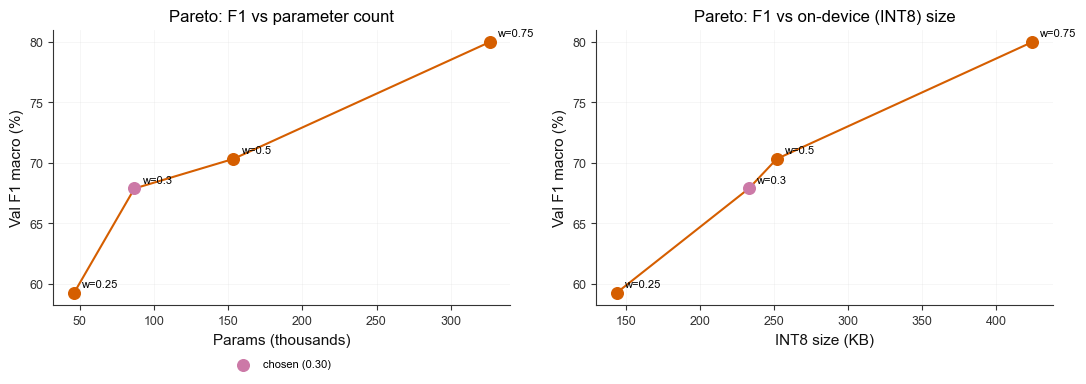

In [46]:
# =============================================================================
# WIDTH_MULT PARETO SWEEP -- CELL 2 of 3
# Figure 10: F1 vs param count, and F1 vs .espdl size -- the two Pareto views the
# backlog note asked for.
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ws = [r["width_mult"] for r in sweep_results]
params_k = [r["params"] / 1000 for r in sweep_results]
sizes = [r["size_kb"] for r in sweep_results]
f1s = [r["f1_macro"] * 100 for r in sweep_results]

for ax, xs, xlabel in [(axes[0], params_k, "Params (thousands)"), (axes[1], sizes, "INT8 size (KB)")]:
    ax.plot(xs, f1s, marker="o", color=C_INT8, linewidth=1.5)
    for x, f1, w in zip(xs, f1s, ws):
        marker_color = C_QAT if w == STUDENT_WIDTH_MULT else C_INT8
        ax.scatter([x], [f1], color=marker_color, s=70, zorder=3,
                   label="chosen (0.30)" if w == STUDENT_WIDTH_MULT else None)
        ax.annotate(f"w={w}", (x, f1), textcoords="offset points", xytext=(6, 4), fontsize=8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Val F1 macro (%)")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_title("Pareto: F1 vs parameter count")
axes[1].set_title("Pareto: F1 vs on-device (INT8) size")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
fig.tight_layout()
save_fig(fig, "fig10_width_mult_pareto.png")
plt.show()


In [47]:
# =============================================================================
# WIDTH_MULT PARETO SWEEP -- CELL 3 of 3
# Summary table + LaTeX export, and the actual justification line for the paper.
# =============================================================================

df_sweep = pd.DataFrame([{
    "width_mult": r["width_mult"], "Params": r["params"], "Size (KB)": round(r["size_kb"], 1),
    "F1 macro (%)": round(r["f1_macro"] * 100, 2), "Accuracy (%)": round(r["accuracy"] * 100, 2),
} for r in sweep_results]).set_index("width_mult")
print(df_sweep.to_string())

sweep_tex_path = os.path.join(MODELS_DIR, "table_width_mult_sweep.tex")
df_sweep.to_latex(sweep_tex_path)
print(f"\nsaved LaTeX table: {sweep_tex_path}")

chosen = next(r for r in sweep_results if r["width_mult"] == STUDENT_WIDTH_MULT)
best_f1_row = max(sweep_results, key=lambda r: r["f1_macro"])
print(f"\nchosen width_mult={STUDENT_WIDTH_MULT}: {chosen['params']:,} params, "
      f"{chosen['size_kb']:.1f} KB, F1={chosen['f1_macro']:.4f}")
if best_f1_row["width_mult"] != STUDENT_WIDTH_MULT:
    delta = (best_f1_row["f1_macro"] - chosen["f1_macro"]) * 100
    print(f"best F1 in the sweep was width_mult={best_f1_row['width_mult']} "
          f"({best_f1_row['f1_macro']:.4f}, +{delta:.2f}pp over the chosen point) at "
          f"{best_f1_row['size_kb']:.1f} KB -- report this trade-off explicitly rather than "
          "implying 0.30 was strictly best; the paper's argument is framework generality, not "
          "that this is the Pareto-optimal width.")


            Params  Size (KB)  F1 macro (%)  Accuracy (%)
width_mult                                               
0.25         46182      143.7         59.27         44.80
0.30         86870      233.0         67.88         56.12
0.50        153526      251.8         70.32         58.66
0.75        326214      424.2         79.95         70.90

saved LaTeX table: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\table_width_mult_sweep.tex

chosen width_mult=0.3: 86,870 params, 233.0 KB, F1=0.6788
best F1 in the sweep was width_mult=0.75 (0.7995, +12.07pp over the chosen point) at 424.2 KB -- report this trade-off explicitly rather than implying 0.30 was strictly best; the paper's argument is framework generality, not that this is the Pareto-optimal width.


## 13 -- Knowledge-Distillation Ablation

Backlog item (Youcef confirmed, "nc"): train a student at `STUDENT_WIDTH_MULT=0.3` directly
on ground truth -- `train_model`, not `train_model_kd` -- same epoch budget, and compare
against the KD student to quantify whether distillation actually helped, rather than assuming
it did because it's in the pipeline.

In [ ]:
# =============================================================================
# KD ABLATION -- CELL 1 of 2
# Loads the "no-KD" comparison model from TinyGestureSSD.ipynb's own trained checkpoint
# (models/best_model.pt, WIDTH_MULT=0.3, plain ground-truth training via train_model, no
# distillation, no pretraining) instead of retraining a fresh no-KD student from scratch
# here -- this is the actual "no pretrain, no KD" reference model from the case study's
# third notebook, reused directly rather than re-created.
#
# Width now matches: TinyGestureSSD.ipynb's WIDTH_MULT was dropped from 0.5 to 0.3 to line
# up with STUDENT_WIDTH_MULT here, so this is a properly width-matched ablation --
# "KD (0.3, distilled from the pretrained teacher)" vs. "no pretrain, no KD (0.3, ground
# truth only)" -- same architecture, same capacity, the only difference is whether
# distillation supervision was used. The `else` branch below (train a fresh width-matched
# no-KD student here) is now a pure fallback for when the standard notebook's checkpoint
# isn't available, not a workaround for a width mismatch.
# =============================================================================

ABLATION_DIR = os.path.join(PROJECT_ROOT, "models_kd_ablation")
os.makedirs(ABLATION_DIR, exist_ok=True)

# TinyGestureSSD.ipynb's own MODELS_DIR ("models/") and checkpoint filename, per that
# notebook's Section 8 (FORCE_RETRAIN checkpoint-resume cell) and Section 1 config cell.
STANDARD_NOTEBOOK_MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
STANDARD_NOTEBOOK_CKPT = os.path.join(STANDARD_NOTEBOOK_MODELS_DIR, "best_model.pt")
STANDARD_NOTEBOOK_WIDTH_MULT = 0.3   # TinyGestureSSD.ipynb's WIDTH_MULT at time of writing --
                                       # see that notebook's Section 1 config cell. If it
                                       # changes there, update this constant to match.

noKD_ckpt_path = os.path.join(ABLATION_DIR, "student_no_kd_best.pt")

if os.path.exists(STANDARD_NOTEBOOK_CKPT):
    print(f"loading no-KD comparison model from TinyGestureSSD.ipynb's checkpoint: "
          f"{STANDARD_NOTEBOOK_CKPT}")
    noKD_model = SSDLiteGestureDetector(width_mult=STANDARD_NOTEBOOK_WIDTH_MULT).to(device)
    noKD_model.load_state_dict(torch.load(STANDARD_NOTEBOOK_CKPT, map_location=device))
    noKD_width_mult = STANDARD_NOTEBOOK_WIDTH_MULT
    noKD_metrics = evaluate(noKD_model, val_loader, anchors_center_d, device)
    noKD_best_f1 = noKD_metrics["f1_macro"]
    noKD_history = None
    noKD_source = "TinyGestureSSD.ipynb (standard, no pretrain, no KD, width-matched, " \
        f"width_mult={STANDARD_NOTEBOOK_WIDTH_MULT})"
else:
    print(f"TinyGestureSSD.ipynb checkpoint not found at {STANDARD_NOTEBOOK_CKPT} -- run that "
          f"notebook's Section 8 first to train it. Falling back to training a fresh, "
          f"width-matched (width_mult={STUDENT_WIDTH_MULT}) no-KD student here instead.")
    noKD_model = SSDLiteGestureDetector(width_mult=STUDENT_WIDTH_MULT).to(device)
    if os.path.exists(noKD_ckpt_path):
        print(f"found existing fallback no-KD checkpoint {noKD_ckpt_path}, loading instead of retraining")
        noKD_model.load_state_dict(torch.load(noKD_ckpt_path, map_location=device))
        noKD_metrics = evaluate(noKD_model, val_loader, anchors_center_d, device)
        noKD_best_f1 = noKD_metrics["f1_macro"]
        noKD_history = None
    else:
        noKD_history, noKD_best_epoch, noKD_best_f1 = train_model(
            noKD_model, train_loader, val_loader, anchors_center_d, anchors_corner_d, device,
            epochs=STUDENT_EPOCHS, checkpoint_name="student_no_kd_best.pt")
        default_path = os.path.join(MODELS_DIR, "student_no_kd_best.pt")
        if os.path.exists(default_path) and default_path != noKD_ckpt_path:
            os.replace(default_path, noKD_ckpt_path)
        noKD_model.load_state_dict(torch.load(noKD_ckpt_path, map_location=device))
    noKD_width_mult = STUDENT_WIDTH_MULT
    noKD_source = f"width-matched fresh training (width_mult={STUDENT_WIDTH_MULT}, no KD)"

print(f"no-KD comparison model: {noKD_source}")
print(f"no-KD val f1_macro={noKD_best_f1:.4f}  (width_mult={noKD_width_mult})")
print(f"KD student (Section 8b): val f1_macro={student_best_f1:.4f}  (width_mult={STUDENT_WIDTH_MULT})")
print(f"KD delta: {(student_best_f1 - noKD_best_f1) * 100:+.2f}pp"
      f"{'  (NOTE: also reflects the width_mult difference, not KD alone)' if noKD_width_mult != STUDENT_WIDTH_MULT else ''}")

TinyGestureSSD.ipynb checkpoint not found at c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models\best_model.pt -- run that notebook's Section 8 first to train it. Falling back to training a fresh, width-matched (width_mult=0.3) no-KD student here instead.
backbone: from-scratch MobileNetV2 (width_mult=0.3) -- no pretrained checkpoint exists at this width


training:   0%|          | 0/120 [00:00<?, ?epoch/s]

epoch 1/120:   0%|          | 0/62 [00:00<?, ?it/s]

validating:   0%|          | 0/7 [00:00<?, ?it/s]

epoch  1/120  total=13.4475  loc=6.8311  cls=6.6164  |  val_acc=0.000  val_prec=0.000  val_rec=0.000  val_f1=0.000  (missed 433/433)  <-- best so far


...

epoch 119/120  total=2.7980  loc=1.0502  cls=1.7478  |  val_acc=0.478  val_prec=0.861  val_rec=0.476  val_f1=0.607  (missed 193/433)


epoch 120/120:   0%|          | 0/62 [00:00<?, ?it/s]

validating:   0%|          | 0/7 [00:00<?, ?it/s]

epoch 120/120  total=2.8634  loc=1.0709  cls=1.7925  |  val_acc=0.462  val_prec=0.859  val_rec=0.460  val_f1=0.595  (missed 201/433)

best checkpoint: epoch 117  f1_macro=0.6118
loaded best checkpoint into the passed-in model and saved it to c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\student_no_kd_best.pt
no-KD comparison model: width-matched fresh training (width_mult=0.3, no KD)
no-KD val f1_macro=0.6118  (width_mult=0.3)
KD student (Section 8b): val f1_macro=0.6978  (width_mult=0.3)
KD delta: +8.61pp


C:\Users\xared\AppData\Local\Temp\ipykernel_25596\3658700927.py:59: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  noKD_model.load_state_dict(torch.load(noKD_ckpt_path, map_l

In [ ]:
# =============================================================================
# KD ABLATION -- CELL 2 of 2
# Figure 11: KD vs no-KD, same width/epochs -- val accuracy/precision/recall/F1 side by side.
#
# Both models are moved to `device` again here, defensively, right before evaluation --
# `student_model` in particular is built and trained several sections earlier (8b), and if
# this cell is re-run after a kernel restart or an out-of-order partial re-run (both common
# in an interactive session), it can silently be sitting on CPU by the time execution
# reaches here even though nothing in between is supposed to move it. That surfaces as
# "Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor) should be the
# same" from evaluate() -> predict_batch_labels() -> the first conv layer, not from
# anything in this cell's own logic. Re-asserting the device here removes the dependency on
# exactly which cells were run before this one.
# =============================================================================

student_model.to(device)
noKD_model.to(device)

noKD_full_metrics = evaluate(noKD_model, val_loader, anchors_center_d, device)
kd_full_metrics = evaluate(student_model, val_loader, anchors_center_d, device)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
labels = ["Accuracy", "Precision", "Recall", "F1 (macro)"]
keys = ["accuracy", "precision", "recall", "f1_macro"]
noKD_vals = [noKD_full_metrics[k] * 100 for k in keys]
kd_vals = [kd_full_metrics[k] * 100 for k in keys]

x = np.arange(len(labels))
w = 0.32
b1 = ax.bar(x - w / 2, noKD_vals, w, label=f"No KD (width={noKD_width_mult}, ground truth only)", color="#999999")
b2 = ax.bar(x + w / 2, kd_vals, w, label=f"KD (width={STUDENT_WIDTH_MULT}, distilled from teacher)", color=C_FP32)

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 1, f"{h:.1f}", ha="center", va="bottom", fontsize=7)

ax.set_ylim(0, 105)
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title("KD ablation: with vs. without distillation" + (" (same width)" if noKD_width_mult == STUDENT_WIDTH_MULT else " (widths differ, see note above)"))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
ax.grid(axis="y")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig11_kd_ablation.png")
plt.show()

df_ablation = pd.DataFrame({
    "No KD": {k: round(noKD_full_metrics[k] * 100, 2) for k in keys},
    "KD (distilled)": {k: round(kd_full_metrics[k] * 100, 2) for k in keys},
}).T
df_ablation.columns = labels
print(df_ablation.to_string())
ablation_tex_path = os.path.join(MODELS_DIR, "table_kd_ablation.tex")
df_ablation.to_latex(ablation_tex_path)
print(f"\nsaved LaTeX table: {ablation_tex_path}")

validating:   0%|          | 0/7 [00:00<?, ?it/s]

validating:   0%|          | 0/7 [00:00<?, ?it/s]

RuntimeError: Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor) should be the same

## 14 -- Calibration Set Sensitivity

Backlog item (Youcef confirmed, "nc"): `ESPDL_CALIB_STEPS` is hardcoded in Section 10 to
`min(200, len(val_loader.dataset))`. This reruns `espdl_quantize_onnx` on the *same* student
ONNX export at several calibration-set sizes and plots INT8 F1 vs calib steps, so the 200
figure is shown to be past the saturation point instead of just asserted.

In [50]:
# =============================================================================
# CALIBRATION SET SENSITIVITY -- CELL 1 of 2
# Re-quantizes the SAME student ONNX (onnx_path from Section 10) at each calib step count --
# only the calibration data volume changes, not the model, so any F1 movement here is purely
# a calibration-quality effect.
#
# Caches the full sweep to disk (models_calib_sweep/calib_results_cache.json) so a rerun
# loads previous results instead of re-quantizing every step count again -- the same
# "carry on from the best/last result" pattern used for the teacher/student checkpoints and
# the QAT cache above. Set FORCE_RERUN_CALIB_SWEEP = True to force a fresh sweep.
# =============================================================================

import json

FORCE_RERUN_CALIB_SWEEP = False   # set True to re-quantize every step count even if cached

CALIB_DIR = os.path.join(PROJECT_ROOT, "models_calib_sweep")
os.makedirs(CALIB_DIR, exist_ok=True)
CALIB_CACHE_PATH = os.path.join(CALIB_DIR, "calib_results_cache.json")

FULL_VAL_STEPS = len(val_loader.dataset)
CALIB_STEP_OPTIONS = sorted(set(s for s in [50, 100, 200, FULL_VAL_STEPS] if s <= FULL_VAL_STEPS))
print(f"calibration set sizes to test: {CALIB_STEP_OPTIONS}  (full val set = {FULL_VAL_STEPS})")

calib_calib_loader = DataLoader(val_loader.dataset, batch_size=1, shuffle=False)

_cached_by_steps = {}
if not FORCE_RERUN_CALIB_SWEEP and os.path.exists(CALIB_CACHE_PATH):
    with open(CALIB_CACHE_PATH) as f:
        _cached_by_steps = {r["calib_steps"]: r for r in json.load(f)}
    print(f"found cached calibration sweep: {CALIB_CACHE_PATH} "
          f"({len(_cached_by_steps)} step counts cached)")

calib_results = []
for steps in CALIB_STEP_OPTIONS:
    if steps in _cached_by_steps:
        print(f"\n=== calib_steps={steps} === loading cached result")
        calib_results.append(_cached_by_steps[steps])
        continue

    print(f"\n=== calib_steps={steps} ===")
    espdl_path = os.path.join(CALIB_DIR, f"student_calib{steps}.espdl")

    # ESPDL_CALIB_STEPS=200 was already run in Section 10 -- reuse that result instead of
    # re-quantizing identically.
    if steps == ESPDL_CALIB_STEPS and os.path.exists(ESPDL_MODEL_PATH):
        print("matches Section 10's ESPDL_CALIB_STEPS -- reusing quant_ppq_graph / metrics_int8")
        calib_results.append({
            "calib_steps": steps, "size_kb": size_int8_kb,
            "f1_macro": metrics_int8["f1_macro"], "accuracy": metrics_int8["accuracy"],
        })
        continue

    graph = espdl_quantize_onnx(
        onnx_import_file=onnx_path, espdl_export_file=espdl_path,
        calib_dataloader=calib_calib_loader, calib_steps=steps,
        input_shape=[1, 3, IMG_SIZE, IMG_SIZE], inputs=None, target=ESPDL_TARGET,
        num_of_bits=ESPDL_NUM_BITS, collate_fn=collate_fn, device=ESPDL_DEVICE,
        error_report=False, skip_export=False, export_test_values=False, verbose=0,
    )
    size_kb = os.path.getsize(espdl_path) / 1024
    executor = TorchExecutor(graph=graph, device=ESPDL_DEVICE)
    metrics, _preds, _gts = evaluate_espdl(executor, val_loader.dataset, anchors_center_d, ESPDL_DEVICE)
    print(f"size={size_kb:.1f} KB  f1_macro={metrics['f1_macro']:.4f}")
    calib_results.append({
        "calib_steps": steps, "size_kb": size_kb,
        "f1_macro": metrics["f1_macro"], "accuracy": metrics["accuracy"],
    })

calib_results.sort(key=lambda r: r["calib_steps"])

with open(CALIB_CACHE_PATH, "w") as f:
    json.dump(calib_results, f, indent=2)
print(f"\ncached calibration sweep -> {CALIB_CACHE_PATH}")


calibration set sizes to test: [50, 100, 200, 433]  (full val set = 433)

=== calib_steps=50 ===
[09:56:10] ConvTranspose Decomposition Pass Running ... Finished.
[09:56:11] PPQ Quantization Fusion Pass Running ...       Finished.
[09:56:11] PPQ Quantize Simplify Pass Running ...         Finished.
[09:56:11] PPQ Parameter Quantization Pass Running ...    Finished.
[09:56:11] PPQ Runtime Calibration Pass Running ...       

Calibration Progress(Phase 2): 100%|██████████| 50/50 [00:03<00:00, 16.21it/s]


Finished.
[09:56:18] PPQ Quantization Alignment Pass Running ...    Finished.
[09:56:18] PPQ Passive Parameter Quantization Running ... Finished.
--------- Network Snapshot ---------
Num of Op:                    [85]
Num of Quantized Op:          [85]
Num of Variable:              [232]
Num of Quantized Var:         [232]
------- Quantization Snapshot ------
Num of Quant Config:          [324]
ACTIVATED:                    [87]
OVERLAPPED:                   [110]
PASSIVE:                      [123]
FP32:                         [4]
Network Quantization Finished.
[INFO][ESPDL][2026-08-17 09:56:18]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:56:18]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:56:18]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:56:18]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:56:18]:  Skip /m/Constant_output

Calibration Progress(Phase 2): 100%|██████████| 100/100 [00:06<00:00, 14.67it/s]


Finished.
[09:57:39] PPQ Quantization Alignment Pass Running ...    Finished.
[09:57:39] PPQ Passive Parameter Quantization Running ... Finished.
--------- Network Snapshot ---------
Num of Op:                    [85]
Num of Quantized Op:          [85]
Num of Variable:              [232]
Num of Quantized Var:         [232]
------- Quantization Snapshot ------
Num of Quant Config:          [324]
ACTIVATED:                    [87]
OVERLAPPED:                   [110]
PASSIVE:                      [123]
FP32:                         [4]
Network Quantization Finished.
[INFO][ESPDL][2026-08-17 09:57:39]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:57:39]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:57:39]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:57:39]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:57:39]:  Skip /m/Constant_output

Calibration Progress(Phase 2): 100%|██████████| 433/433 [00:26<00:00, 16.56it/s]


Finished.
[09:59:26] PPQ Quantization Alignment Pass Running ...    Finished.
[09:59:26] PPQ Passive Parameter Quantization Running ... Finished.
--------- Network Snapshot ---------
Num of Op:                    [85]
Num of Quantized Op:          [85]
Num of Variable:              [232]
Num of Quantized Var:         [232]
------- Quantization Snapshot ------
Num of Quant Config:          [324]
ACTIVATED:                    [87]
OVERLAPPED:                   [110]
PASSIVE:                      [123]
FP32:                         [4]
Network Quantization Finished.
[INFO][ESPDL][2026-08-17 09:59:26]:  Skip /m/Constant_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:59:26]:  Skip /m/Constant_2_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:59:26]:  Skip /m/Constant_1_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:59:26]:  Skip /m/Constant_3_output_0 because it's not exportable
[INFO][ESPDL][2026-08-17 09:59:26]:  Skip /m/Constant_output

saved: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\fig12_calib_steps_sensitivity.png


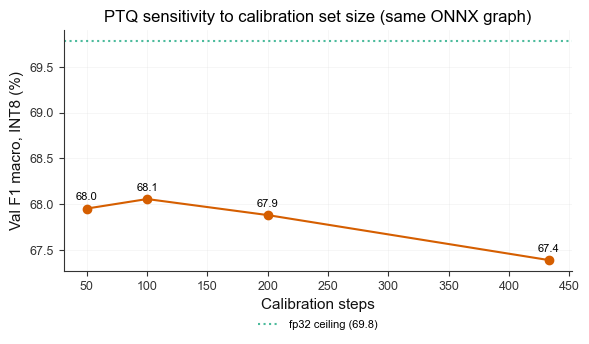

              Size (KB)  F1 macro (raw)  Accuracy (raw)
calib_steps                                            
50           183.984375        0.679515        0.563510
100          183.984375        0.680558        0.558891
200          232.984375        0.678802        0.561201
433          183.984375        0.673879        0.549654

saved LaTeX table: c:\Users\xared\Documents\30_PROJECTS\TinyGestureSSD\TinyGestureSSD\models_kd\table_calib_steps_sensitivity.tex

200->433 calib steps moved F1 by -0.49pp -- saturated.


In [51]:
# =============================================================================
# CALIBRATION SET SENSITIVITY -- CELL 2 of 2
# Figure 12: INT8 F1 vs calibration steps -- where does it saturate?
# =============================================================================

fig, ax = plt.subplots(figsize=(6, 3.6))
steps_x = [r["calib_steps"] for r in calib_results]
f1_y = [r["f1_macro"] * 100 for r in calib_results]

ax.plot(steps_x, f1_y, marker="o", color=C_INT8, linewidth=1.5)
for x, y in zip(steps_x, f1_y):
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 6),
                ha="center", fontsize=8)
ax.axhline(metrics_fp32["f1_macro"] * 100, color=C_FP32, linestyle=":", alpha=0.7,
           label=f"fp32 ceiling ({metrics_fp32['f1_macro']*100:.1f})".replace("'", "'"))
ax.set_xlabel("Calibration steps")
ax.set_ylabel("Val F1 macro, INT8 (%)")
ax.set_title("PTQ sensitivity to calibration set size (same ONNX graph)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8, frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig12_calib_steps_sensitivity.png")
plt.show()

df_calib = pd.DataFrame(calib_results).set_index("calib_steps")
df_calib.columns = ["Size (KB)", "F1 macro (raw)", "Accuracy (raw)"]
print(df_calib.to_string())
calib_tex_path = os.path.join(MODELS_DIR, "table_calib_steps_sensitivity.tex")
df_calib.to_latex(calib_tex_path)
print(f"\nsaved LaTeX table: {calib_tex_path}")

# saturation check: does going from the second-largest to the largest calib set move F1 by
# less than 0.5pp? If so, 200 (or whatever the second-largest tested value is) is a reasonable
# operating point, not an arbitrary one.
if len(calib_results) >= 2:
    last, prev = calib_results[-1], calib_results[-2]
    delta = (last["f1_macro"] - prev["f1_macro"]) * 100
    print(f"\n{prev['calib_steps']}->{last['calib_steps']} calib steps moved F1 by "
          f"{delta:+.2f}pp -- {'saturated' if abs(delta) < 0.5 else 'still moving, consider more steps'}."
          .replace("'", "'"))
